# Gwangyang: can rtDD reproduce the user's HypoDD relocation?

**What is checked.** SED's real-time double-difference relocator **rtDD** exists in two forms: **pyrtdd**, a Python
package around its C++ engine (libhdd), and **scrtdd**, the SeisComP module built on the same engine. Both were run on
the Gwangyang benchmark (a tight cluster of small KMA events; listed in section 1.2) with settings chosen to mimic the user's
**HypoDD** reference run, and their results were compared with HypoDD (notes `docs/results/07_gwangyang_pyrtdd.md` and
`08_gwangyang_scrtdd.md`; numbers corrected after an independent verification, `fixes_after_verification.md`). All
computations are done. This notebook only **loads** the result files and shows them; nothing is relocated here.

**Terms used throughout, in plain words**

- *Relocation, double difference*: an earthquake's position is found from wave arrival times. Double-difference
  relocation uses, for each pair of nearby events and each station, the *difference* of their travel times. Errors
  shared by both events (the path to the station, the velocity model) cancel, so the events' positions *relative to
  each other* come out much better than their absolute positions.
- *Catalog differential times*: travel-time differences computed from the picked arrival times (HypoDD file
  `dt.ct`). *Cross-correlation differential times*: the same, but measured by sliding one event's waveform over the
  other's until they match best (HypoDD file `dt.cc`); much more precise for similar events.
- *CC (correlation coefficient)*: how similar two waveforms are, from -1 (mirror images) through 0 to +1 (identical
  shape). Measurements below 0.7 are discarded.
- *Band-pass filter*: keeps only a chosen frequency range of a waveform before it is cross-correlated.
- *HypoDD dt.cc / dt.ct*: the user's two HypoDD solutions, with cross-correlation plus catalog times and with
  catalog times only.
- *Bootstrap 95% half-width*: HypoDD was re-run many times on resampled data, starting from its own solution with
  the same settings. Half of the range that holds 95% of the re-run positions is the half-width (east, north, up).
  It measures only how stable HypoDD's own solution is (its *precision*), not whether it is right.
- *Centroid*: the average position of all events of one solution.
- *Shape difference*: each event's position relative to its own solution's centroid, minus the same for HypoDD. Its
  root-mean-square (RMS) over the events, horizontally and vertically, says how different the cluster *shapes* are,
  whatever the cluster's absolute position.
- *Inter-event distance*: the 3-D distance between two events of the same solution, for every pair of events.
- *Damping* and *absLocConstraint*: two rtDD solver settings. Damping penalizes large position changes in each
  iteration; absLocConstraint adds equations that tie each event to its absolute arrival times. With
  absLocConstraint 0 only the damping keeps the cluster as a whole from sliding.
- *Single-event (real-time) mode*: a new event is relocated alone against a fixed catalog of already relocated
  events, as rtDD does in real time. *Leave-one-out*: each event in turn is removed from the catalog and relocated
  against all the others.

**The solutions shown** (names as in notes 07 and 08; the full settings table follows in section 1)

| name | program | what it is |
|---|---|---|
| S0, R0 | scrtdd, pyrtdd | catalog differential times only (analogue of HypoDD dt.ct) |
| S1 | scrtdd | catalog plus cross-correlation set up like the reference (analogue of HypoDD dt.cc) |
| R1 | pyrtdd | the same settings as S1, stock pyrtdd: the band-pass filter is silently **not** applied |
| R1f | pyrtdd | as R1, with the band-pass really applied (pre-processing done in a proxy subclass) |
| S2, R2, R2f | scrtdd, pyrtdd | rtDD's default solver (with absLocConstraint) and default cross-correlation windows |
| S2sc | scrtdd | scrtdd's own profile defaults (out of the box) |
| R1fz, R1fw, R3*, R4*, R5*, S0h, S1h | pyrtdd, scrtdd | one setting changed: zero-phase filter, xcorrWeightScaler, start at HYPOINVERSE, outlier picks removed, homogeneous velocity |
| SEa, SEm | scrtdd | single event, leave-one-out against S1, automatic or manual picks (scrtdd's two steps) |
| R6f, R6tf | pyrtdd | single event, leave-one-out against R1f, filter applied: one step, or scrtdd's two steps |

**Contents**

0. Parameters
1. Loading, cross-file consistency checks, events, settings
2. Figure 1: the cluster in map view and two vertical sections
3. Figure 2: per-event differences from HypoDD, with HypoDD's bootstrap half-widths
4. Figure 3: inter-event distances
5. Figure 4: cross-correlation measurements against the reference dt.cc
6. Figure 5: the pyrtdd filter bug
7. Figure 6: pyrtdd and scrtdd give the same numbers
8. Figure 7: the absolute position slides (centroid drift)
9. Figure 8: single-event (real-time style) relocation
10. Figure 9: which settings matter
11. Comprehensive summary

## 0. Parameters

Every setting of this notebook is in the next cell: input files, the color and marker of each solution, figure
choices, histogram bins and the tolerances of the consistency checks. Nothing further down changes them.

In [1]:
# ============================== PARAMETERS ==============================
# every setting of this notebook; nothing below changes these values (the markdown text quotes them)
import time as _time
T_START = _time.time()                            # the run time is printed at the very end
PROJECT = "/home/msseo/works/74.SeisComP_rtDD_DLpicker"
LIB = f"{PROJECT}/notebooks/lib"                  # nbfont.py (Helvetica) and nb02_helpers.py
FIG_DIR = f"{PROJECT}/notebooks/figures"          # every figure as 02_*.png and 02_*.pdf
FIG_DPI = 200                                     # resolution of the PNG files

# --- reference tables (HypoDD run on server B; read-only copies) ---
REF = f"{PROJECT}/data/gwangyang_11ev/reference_tables"
EVENT_ID_MAP = f"{REF}/event_id_map.csv"          # rtDD id 1-11, KMA id, KMA origin time, KMA ML
HYPODD_DTCC = f"{REF}/hypodd_dtcc.csv"            # HypoDD 02.dt.cc (bootstrap count n_boot; rounded half-widths for a check)
HYPODD_DTCT = f"{REF}/hypodd_dtct.csv"            # HypoDD 01.dt.ct
DTCC_MEASURED = f"{REF}/dtcc_measured.csv"        # every reference cross-correlation measurement (any CC)
DTCC_USED = f"{REF}/dtcc_used.csv"                # reference dt.cc with CC >= 0.7, with HypoDD's final-iteration keep flag

# --- pyrtdd results (note 07) ---
PY = f"{PROJECT}/runs/gwangyang/pyrtdd"
PY_SUMMARY = f"{PY}/summary_metrics.csv"          # one row per run and reference: metrics (a)-(f)
PY_PER_EVENT = f"{PY}/per_event_vs_reference.csv" # per run, reference and event; unrounded bootstrap half-widths
PY_RUN_VS_RUN = f"{PY}/run_vs_run_metrics.csv"    # sensitivity pairs (section 5 of note 07)
PY_PER_EVENT_RVR = f"{PY}/per_event_run_vs_run.csv"   # per event for those pairs (single-event runs: section 7)
PY_XCORR = f"{PY}/xcorr_comparison.csv"           # cross-correlation vs reference, per run and subset
PY_POSITIONS = f"{PY}/positions_enu.csv"          # every solution's positions (local east/north/up)
PY_ANALYSIS = f"{PY}/analysis_summary.json"       # run list, local origin, HypoDD convention, special event
PY_DRIFT = f"{PY}/diag_centroid_drift/diag_centroid_drift.csv"    # centroid drift vs iterations and damping
PY_FILTER_TEST = f"{PY}/checks/filter_effect_test/filter_effect_test.json"   # the five 'filters'
PY_RELOCATED = f"{PY}/{{run}}/relocated-event.csv"    # relocated catalog of each run ({run} = full run name)
PY_OPTIONS = f"{PY}/{{run}}/options.json"             # every option of each run, read back from libhdd
PY_RUN_INFO = f"{PY}/{{run}}/run_info.json"           # counters (filter() calls received by the proxy)

# --- scrtdd results (note 08) ---
SCC = f"{PROJECT}/runs/gwangyang/scrtdd/comparison"
SC_METRICS = f"{SCC}/metrics_vs_hypodd.csv"
SC_PER_EVENT = f"{SCC}/per_event_vs_hypodd.csv"
SC_POSITIONS = f"{SCC}/positions_enu.csv"         # all solutions, both programs (up to 0.1 mm)
SC_RUN_VS_RUN = f"{SCC}/run_vs_run.csv"
SC_VS_PY_SUMMARY = f"{SCC}/scrtdd_vs_pyrtdd_summary.csv"
SC_VS_PY_PER_EVENT = f"{SCC}/scrtdd_vs_pyrtdd_per_event.csv"
SC_XCORR_VS_REF = f"{SCC}/xcorr_vs_reference.csv"
SC_TRIPLETS_REF = f"{SCC}/xcorr_triplets_S1_vs_reference.csv"   # S1 differential times next to the reference ones
SC_TRIPLETS_S1_R1F = f"{SCC}/xcorr_triplets_S1_vs_R1f.csv"      # S1 and R1f lags and CC, triplet by triplet
SC_XCORR_SC_VS_PY = f"{SCC}/xcorr_scrtdd_vs_pyrtdd.csv"
SC_SINGLE = f"{SCC}/single_event_vs_S1.csv"       # SEa / SEm minus S1, per event (start, step 1, final)
SC_SINGLE_SUMMARY = f"{SCC}/single_event_vs_S1_summary.csv"
SC_SINGLE_CONTEXT = f"{SCC}/single_event_context.csv"
SC_SUMMARY = f"{SCC}/summary.json"
SC_OPTIONS = f"{SCC}/options_by_run.csv"          # every option of each scrtdd run
SC_RUN_OPTIONS = f"{PROJECT}/runs/gwangyang/scrtdd/{{run}}/run_options.json"   # module and profile options of each scrtdd run

# --- pyrtdd source (Figure 5) ---
PROXY_EXT_CPP = f"{PROJECT}/software/src/pyrtdd/package/src/pyrtdd/hdd/proxy_ext.cpp"
PROXY_EXT_LINES = (78, 79)                        # the filter() override of the pybind11 trampoline

# --- solutions: one color and marker each, the same in every figure (Okabe-Ito colors, plus Paul Tol's indigo,
#     cyan, wine and olive for the single-event runs) ---
STYLE = {
    "hypodd_dtcc": dict(label="HypoDD dt.cc (reference)", color="#000000", marker="o", filled=True),
    "hypodd_dtct": dict(label="HypoDD dt.ct (catalog times only)", color="#808080", marker="o", filled=False),
    "S1": dict(label="scrtdd S1 (cross-correlation)", color="#0072B2", marker="s", filled=False),
    "R1f": dict(label="pyrtdd R1f (cross-correlation, filter applied)", color="#E69F00", marker="^", filled=False),
    "R1": dict(label="pyrtdd R1 (stock: filter silently not applied)", color="#D55E00", marker="v", filled=False),
    "S2": dict(label="scrtdd S2 (rtDD default solver and windows)", color="#009E73", marker="D", filled=False),
    "S0": dict(label="scrtdd S0 (catalog times only)", color="#CC79A7", marker="P", filled=True),
    "R0": dict(label="pyrtdd R0 (catalog times only)", color="#CC79A7", marker="X", filled=False),
    "SEa": dict(label="scrtdd single event, automatic picks (SEa)", color="#332288", marker="<", filled=True),
    "SEm": dict(label="scrtdd single event, manual picks (SEm)", color="#88CCEE", marker=">", filled=True),
    "R6f": dict(label="pyrtdd single event, one step (R6f)", color="#882255", marker="h", filled=True),
    "R6tf": dict(label="pyrtdd single event, scrtdd's two steps (R6tf)", color="#999933", marker="p", filled=True),
}
MS = 6.0                       # marker size (points)
MEW = 1.1                      # marker edge width

# --- figures ---
F1_SOLUTIONS = ["S1", "R1f", "R1"]          # drawn over HypoDD dt.cc in Figure 1
F1_IN_PER_M = 0.046                         # Figure 1 scale: inches per meter (equal in every panel)
F1_PAD_M = 6.0                              # margin around the outermost point or error bar
F1_ZOOM_EVENTS = [1, 2, 3, 7, 8, 9]         # Figure 1 b: the crowded western group, shown again at a larger scale
F1_ZOOM_PAD_M = 2.5                         # margin of the zoom around those events' positions (error bars may be cut)
F2_XCORR = ["S1", "R1f", "R1", "S2"]        # Figure 2, left column (against HypoDD dt.cc)
F2_CATALOG = ["S0"]                         # Figure 2, right column (against HypoDD dt.ct)
F2_JITTER = 0.18                            # horizontal spread of the solutions around each event number
HIST_INNER_MS = 5                           # Figure 4: 1-ms bins from -5 to +5 ms ...
HIST_OUTER_EDGES_MS = [5.5, 10.0, 20.0, 50.0, 100.0, 200.0, 500.0, 1000.0]   # ... wider bins beyond (both signs)
HIST_LINTHRESH_MS = 5.5                     # symmetric-log axis: linear within +-5.5 ms
HIST_LINSCALE = 1.6
WITHIN_MS = (2, 5)                          # agreement limits, counted on the 1-ms grid (as notes 07/08)
CC_MIN = 0.7                                # cross-correlation acceptance (|CC| in rtDD, CC in the reference)
F4_RUNS = ["S1", "S2", "R1"]                # Figure 4 c: rtDD runs whose counts are shown next to the reference
F5_RUNS = ["R1", "R1f", "S1"]               # Figure 5 c, d
F5_CASE_LABELS = {"none": "No filter", "bp5_20": "Band-pass\n5-20 Hz", "lp1": "Low-pass\n1 Hz",
                  "zeroing": "Sets every\nsample to 0", "negating": "Flips the\nsign"}
F5_TICK_LABELS = {"R1": "pyrtdd R1\n(stock, no filter)", "R1f": "pyrtdd R1f\n(filter applied)", "S1": "scrtdd S1"}
F5_EXPECTED = {"none": "(baseline)", "bp5_20": "should change", "lp1": "should change",
               "zeroing": "should fail", "negating": "unchanged:\nboth traces flip"}
F8_ZOOM_M = 2.5                             # Figure 8 b: axis limit of the zoom (m)
RECOMMENDED_MIN_DAMPING = 0.1               # recommendation tested in Figure 7 (or absLocConstraint > 0)
F9_ITEMS = [                                # Figure 9: (category, [(tool, base run, changed run), ...])
    ("Cross-correlation vs catalog times only", [("pyrtdd", "R0", "R1"), ("scrtdd", "S0", "S1")]),
    ("Homogeneous velocity instead of the kim1983 grids", [("pyrtdd", "R1", "R5"), ("pyrtdd", "R1f", "R5f")]),
    ("Band-pass applied vs not applied", [("pyrtdd", "R1", "R1f")]),
    ("rtDD default solver and default windows", [("pyrtdd", "R1", "R2"), ("pyrtdd", "R1f", "R2f"), ("scrtdd", "S1", "S2")]),
    ("scrtdd profile defaults (out of the box)", [("scrtdd", "S1", "S2sc")]),
    ("Zero-phase vs causal band-pass", [("pyrtdd", "R1f", "R1fz")]),
    ("Outlier picks removed", [("pyrtdd", "R1", "R4"), ("pyrtdd", "R1f", "R4f")]),
    ("Start at HYPOINVERSE instead of the centroid", [("pyrtdd", "R0", "R3a"), ("pyrtdd", "R1", "R3b"),
                                                      ("pyrtdd", "R1f", "R3bf"), ("scrtdd", "S0", "S0h"),
                                                      ("scrtdd", "S1", "S1h")]),
    ("xcorrWeightScaler", [("pyrtdd", "R1f", "R1fw")]),
]
F9_XLIM_M = (0.01, 100.0)                   # Figure 9: logarithmic axis range

# --- cross-file consistency checks (tolerances) ---
TOL_POS_M = 0.06            # the same solution in two position tables (pyrtdd writes depth to 0.1 m: 0.05 m + slack)
TOL_METRIC_M = 0.06         # a metric recomputed here from positions vs the value in the result file
TOL_SAME_FILE_M = 0.01      # the same metric in the pyrtdd and the scrtdd tables
TOL_BOOT_ROUND_M = 0.051    # unrounded vs 0.1-m rounded bootstrap half-widths

In [2]:
# imports, Helvetica, versions, plotting style
import os
import sys
import json
import textwrap
import importlib
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from IPython.display import display, Markdown
import obspy
from obspy.geodetics import gps2dist_azimuth

sys.path.insert(0, "/home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/lib")
import nbfont
FONT_FAMILY = nbfont.use_helvetica(verbose=True)
print("resolved font family:", FONT_FAMILY, "| font file matplotlib uses for text:",
      matplotlib.font_manager.findfont(matplotlib.font_manager.FontProperties(family=["sans-serif"])))
import nb02_helpers as hp
importlib.reload(hp)

plt.rcParams.update({"font.size": 9, "axes.titlesize": 9.5, "axes.labelsize": 9, "legend.fontsize": 8,
                     "xtick.labelsize": 8, "ytick.labelsize": 8, "figure.dpi": 100,
                     "mathtext.cal": "Helvetica:italic"})   # unused calligraphic slot; avoids a 'cursive' font lookup
os.makedirs(FIG_DIR, exist_ok=True)
pd.set_option("display.width", 230)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 120)
pd.set_option("display.max_colwidth", 120)

ML = r"$\mathit{M}_{\mathrm{L}}$"
FIGS = {}


def mk(key, ms=None, filled=None, **over):
    # plot keywords of one solution (same color and marker in every figure)
    s = STYLE[key]
    f = s["filled"] if filled is None else filled
    kw = dict(ls="none", marker=s["marker"], ms=MS if ms is None else ms, mec=s["color"],
              mfc=s["color"] if f else "white", mew=MEW, color=s["color"])
    kw.update(over)
    return kw


def plain_log(ax, axis="y"):
    # logarithmic axis labeled 0.1, 1, 10, ... instead of powers of ten
    from matplotlib.ticker import FuncFormatter
    getattr(ax, f"{axis}axis").set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))


def handle(key, **over):
    return Line2D([], [], **mk(key, **over))


def md_table(df, index=True):
    # pandas -> markdown table (so that column titles can carry formatted text)
    d = df.reset_index() if index else df
    lines = ["| " + " | ".join(str(c) for c in d.columns) + " |", "|" + "---|" * len(d.columns)]
    for row in d.itertuples(index=False):
        lines.append("| " + " | ".join(str(v) for v in row) + " |")
    return "\n".join(lines)


print("versions: numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__,
      "| obspy", obspy.__version__)

font family in use: Helvetica (8 faces registered)
resolved font family: Helvetica | font file matplotlib uses for text: /home/msseo/.local/share/fonts/helvetica-family/Helvetica-Regular.otf
versions: numpy 2.5.4 | pandas 3.0.6 | matplotlib 3.11.2 | obspy 1.5.1


## 1. Loading the result files

Every table of notes 07 and 08 that the figures use is read here. Run names are shortened to their first token
(`R1f_xcorr_like_reference_hypodd_like_filtered` becomes `R1f`).

In [3]:
# 1. load every result table (nothing is relocated)
EVMAP = pd.read_csv(EVENT_ID_MAP).set_index("rtdd_id").sort_index()
HDCC = pd.read_csv(HYPODD_DTCC).set_index("rtdd_id").sort_index()
HDCT = pd.read_csv(HYPODD_DTCT).set_index("rtdd_id").sort_index()
DT_MEAS = pd.read_csv(DTCC_MEASURED)
DT_USED = pd.read_csv(DTCC_USED)

PY_AN = hp.read_json(PY_ANALYSIS)
RUNS = {hp.short(r): r for r in PY_AN["runs"]}                 # short name -> full pyrtdd run name
EV3 = int(PY_AN["special_event"])                              # the event with the reference's special window
ORIGIN = tuple(PY_AN["origin"])                                # local east/north/up origin of both notes
PY_SUM = pd.read_csv(PY_SUMMARY)
PY_SUM["short"] = PY_SUM.run.map(hp.short)
PY_PE = pd.read_csv(PY_PER_EVENT)
PY_PE["short"] = PY_PE.run.map(hp.short)
PY_RVR = pd.read_csv(PY_RUN_VS_RUN)
PY_RVR["b"], PY_RVR["o"] = PY_RVR.base.map(hp.short), PY_RVR.other.map(hp.short)
PY_PERVR = pd.read_csv(PY_PER_EVENT_RVR)
PY_PERVR["b"], PY_PERVR["o"] = PY_PERVR.base.map(hp.short), PY_PERVR.other.map(hp.short)
PY_XC = pd.read_csv(PY_XCORR)
PY_XC["short"] = PY_XC.run.map(hp.short)
PY_POS = pd.read_csv(PY_POSITIONS)
PY_POS["key"] = [s if s.startswith(("hypodd", "hypoinverse")) else hp.short(s) for s in PY_POS.solution]
DRIFT = pd.read_csv(PY_DRIFT)
DRIFT["b"] = DRIFT.base.map(hp.short)
FILTER_TEST = hp.read_json(PY_FILTER_TEST)

SC_MET = pd.read_csv(SC_METRICS)
SC_MET["key"] = SC_MET.solution.map(hp.short)
SC_PE = pd.read_csv(SC_PER_EVENT)
SC_PE["key"] = SC_PE.solution.map(hp.short)
SC_POS = pd.read_csv(SC_POSITIONS)
SC_POS["key"] = [hp.short(s) if p == "pyrtdd" else s for p, s in zip(SC_POS.program, SC_POS.solution)]
SC_RVR = pd.read_csv(SC_RUN_VS_RUN)
SC_PY_SUM = pd.read_csv(SC_VS_PY_SUMMARY)
SC_PY_SUM["py"] = SC_PY_SUM.pyrtdd.map(hp.short)
SC_PY_PE = pd.read_csv(SC_VS_PY_PER_EVENT)
SC_PY_PE["py"] = SC_PY_PE.pyrtdd.map(hp.short)
SC_XREF = pd.read_csv(SC_XCORR_VS_REF)
SC_XREF["key"] = SC_XREF.run.map(hp.short)
TRIP_REF = pd.read_csv(SC_TRIPLETS_REF)
TRIP_S1R1F = pd.read_csv(SC_TRIPLETS_S1_R1F)
SC_XSCPY = pd.read_csv(SC_XCORR_SC_VS_PY)
SC_XSCPY["py"] = SC_XSCPY.pyrtdd.map(hp.short)
SE = pd.read_csv(SC_SINGLE)
SE_SUM = pd.read_csv(SC_SINGLE_SUMMARY).set_index("mode")
SE_CTX = pd.read_csv(SC_SINGLE_CONTEXT)
SE_CTX["run"] = SE_CTX.single_event_run.map(hp.short)
SE_CTX["vs"] = SE_CTX.versus.map(hp.short)
SC_SUMJ = hp.read_json(SC_SUMMARY)
SC_OPT = pd.read_csv(SC_OPTIONS, index_col=0)

EVENTS = list(EVMAP.index)
N_EV = len(EVENTS)
N_PAIRS = N_EV * (N_EV - 1) // 2
print(f"{N_EV} events; {len(RUNS)} pyrtdd runs; scrtdd runs {sorted(SC_MET[SC_MET.program == 'scrtdd'].key.unique())}; "
      f"special event {EV3}; local origin {ORIGIN}")
print("HypoDD convention of both notes:", PY_AN["hypodd_convention"])
print("pyrtdd inputs read by the scrtdd comparison (modification times, KST):")
for k, v in dict(SC_SUMJ["pyrtdd_inputs_mtime_kst"]).items():
    print("  ", hp.short(k), v)

11 events; 22 pyrtdd runs; scrtdd runs ['S0', 'S0h', 'S0n', 'S1', 'S1h', 'S2', 'S2sc']; special event 3; local origin (35.0, 127.7286)
HypoDD convention of both notes: hypoDD.log 'Cluster centroid at' + hypoDD.reloc X/Y/Z (0.1 m); bootstrap half-widths unrounded from bootstrap_errors.csv
pyrtdd inputs read by the scrtdd comparison (modification times, KST):
   R0 2026-10-17T16:48:05.339283943+09:00
   R1 2026-10-17T16:48:30.422284365+09:00
   R1f 2026-10-17T16:50:16.097286224+09:00
   R1fw 2026-10-17T16:56:12.392292500+09:00
   R1fz 2026-10-17T16:50:57.795286894+09:00
   R2 2026-10-17T16:51:29.447287560+09:00
   R2f 2026-10-17T16:52:20.543288469+09:00
   R3a 2026-10-17T16:52:20.889288425+09:00
   R3b 2026-10-17T16:52:44.634288788+09:00
   R3bf 2026-10-17T16:53:25.256289482+09:00
   R4 2026-10-17T16:53:48.635289907+09:00
   R4f 2026-10-17T16:54:28.020290613+09:00
   R5 2026-10-17T16:54:52.032291174+09:00
   R5f 2026-10-17T16:55:32.156291962+09:00
   R6 2026-10-17T16:56:20.911316633+09:0

In [4]:
# 1. accessors: positions, per-event differences, metrics and bootstrap half-widths of any solution
SCRTDD = set(SC_MET[SC_MET.program == "scrtdd"].key)


def pos(key):
    # east/north/up (m) of a solution, from the scrtdd comparison table (both programs; up to 0.1 mm)
    d = SC_POS[SC_POS.key == key].set_index("id").sort_index()
    assert list(d.index) == EVENTS, key
    return d[["E", "N", "U"]].astype(float)


def pos_py(key):
    # the same from the pyrtdd table (depth written to 0.1 m)
    d = PY_POS[PY_POS.key == key].set_index("event_id").sort_index()
    return d[["east_m", "north_m", "up_m"]].set_axis(["E", "N", "U"], axis=1).astype(float)


def per_event(key, ref):
    # each event's shape difference (relative to own centroid) from a HypoDD solution, dE/dN/dU in m
    if key in SCRTDD:
        d = SC_PE[(SC_PE.program == "scrtdd") & (SC_PE.key == key) & (SC_PE.versus == ref)].set_index("id")
        d = d[["dE_m", "dN_m", "dU_m"]]
    else:
        d = PY_PE[(PY_PE.short == key) & (PY_PE.reference == ref)].set_index("event_id")
        d = d[["dE_rel_m", "dN_rel_m", "dU_rel_m"]]
    return d.set_axis(["dE", "dN", "dU"], axis=1).sort_index().astype(float)


def met(key, ref):
    # metrics (a)-(e) of a solution against a HypoDD solution; inside counts against that solution's own box
    if key == "hypodd_dtct":
        r = PY_SUM[(PY_SUM.run == "REF_hypodd_dtct") & (PY_SUM.reference == ref)].iloc[0]
    elif key in SCRTDD:
        r = SC_MET[(SC_MET.program == "scrtdd") & (SC_MET.key == key) & (SC_MET.versus == ref)].iloc[0]
        own = "boot95" if ref == "hypodd_dtcc" else "boot_own95"
        return dict(rms_h=r.rms_h_m, max_h=r.max_h_m, rms_v=r.rms_v_m, max_v=r.max_v_m, max_3d=r.max_3d_m,
                    n_in=int(r[f"n_inside_{own}"]), ratio=float(r[f"max_ratio_{own}"]),
                    ratio_ev=int(r[f"max_ratio_{own}_event"]), r=r.interevent_pearson_r,
                    rms_d=r.interevent_rms_diff_m, b=(r.centroid_shift_E_m, r.centroid_shift_N_m, r.centroid_shift_U_m),
                    ot_rms=r.origin_time_rms_ms)
    else:
        r = PY_SUM[(PY_SUM.short == key) & (PY_SUM.reference == ref)].iloc[0]
    return dict(rms_h=r.a_rel_rms_h_m, max_h=r.a_rel_max_h_m, rms_v=r.a_rel_rms_v_m, max_v=r.a_rel_max_v_m,
                max_3d=np.nan, n_in=int(r.c_n_inside_boot95), ratio=float(r.c_max_ratio), ratio_ev=int(r.c_max_ratio_event),
                r=r.d_interevent_pearson_r, rms_d=r.d_interevent_rms_diff_m,
                b=(r.b_centroid_shift_e_m, r.b_centroid_shift_n_m, r.b_centroid_shift_u_m), ot_rms=r.e_ot_rms_demeaned_ms)


def boot(ref):
    # unrounded bootstrap 95% half-widths of a HypoDD solution (identical in every run's rows; checked below)
    d = PY_PE[PY_PE.reference == ref]
    g = d.groupby("event_id")[["boot_ex95_m", "boot_ey95_m", "boot_ez95_m"]]
    assert float((g.max() - g.min()).to_numpy().max()) == 0.0, "half-widths differ between runs"
    return g.first().set_axis(["ex", "ey", "ez"], axis=1).sort_index()


BOOT_CC, BOOT_CT = boot("hypodd_dtcc"), boot("hypodd_dtct")
N_BOOT = int(HDCC.n_boot.iloc[0])
WELL = [e for e in EVENTS if e != EV3]          # the ten events other than the special one
print(f"bootstrap: {N_BOOT} resamples; dt.cc half-widths for the {len(WELL)} other events: horizontal "
      f"{BOOT_CC.loc[WELL, ['ex', 'ey']].to_numpy().min():.2f}-{BOOT_CC.loc[WELL, ['ex', 'ey']].to_numpy().max():.2f} m, "
      f"vertical {BOOT_CC.loc[WELL, 'ez'].min():.2f}-{BOOT_CC.loc[WELL, 'ez'].max():.2f} m; event {EV3}: "
      + " / ".join(f"{v:.2f}" for v in BOOT_CC.loc[EV3]) + " m (E / N / U)")

bootstrap: 1000 resamples; dt.cc half-widths for the 10 other events: horizontal 1.70-4.80 m, vertical 3.30-6.85 m; event 3: 16.20 / 6.15 / 25.65 m (E / N / U)


### 1.1 Cross-file consistency checks

The same quantity is often stored in more than one file (pyrtdd's and scrtdd's comparison tables, the relocated
catalogs, the reference tables). Here each such pair is compared, and every metric that a figure shows is recomputed
from the positions and compared with the stored value. A check fails if the difference exceeds its tolerance
(parameter cell). Failed checks are listed again in the summary.

In [5]:
# 1.1 consistency checks between files (values A and B of the same quantity)
CHECKS = []

# (i) the same solution in the two position tables (absolute east/north/up; pyrtdd writes depth to 0.1 m)
for key in ("hypodd_dtcc", "hypodd_dtct", "R0", "R1", "R1f", "R6f", "R6tf"):
    a, b = pos(key), pos_py(key)
    d = a - b
    CHECKS.append(hp.check_row(f"positions of {key}: scrtdd table vs pyrtdd table, largest |difference| (m)",
                               np.abs(d.to_numpy()).max(), 0.0, TOL_POS_M))

# (ii) the positions table vs the run's own relocated catalog (east/north from ObsPy gps2dist_azimuth, up = -depth)
for key in ("R0", "R1", "R1f"):
    cat = pd.read_csv(PY_RELOCATED.format(run=RUNS[key])).set_index("id").sort_index()
    enu = []
    for la, lo, de in zip(cat.latitude, cat.longitude, cat.depth):
        dist, az, _ = gps2dist_azimuth(ORIGIN[0], ORIGIN[1], la, lo)
        enu.append((dist * np.sin(np.radians(az)), dist * np.cos(np.radians(az)), -1000.0 * de))
    CHECKS.append(hp.check_row(f"positions of {key}: table vs {RUNS[key]}/relocated-event.csv (m)",
                               np.abs(np.array(enu) - pos(key).to_numpy()).max(), 0.0, TOL_POS_M))

# (iii) shape metrics and inter-event distances recomputed from the positions vs the stored values
for key, ref in (("S1", "hypodd_dtcc"), ("S2", "hypodd_dtcc"), ("R1f", "hypodd_dtcc"), ("R1", "hypodd_dtcc"),
                 ("S0", "hypodd_dtct"), ("S0", "hypodd_dtcc")):
    sm = hp.shape_metrics(pos(key).to_numpy(), pos(ref).to_numpy())
    m = met(key, ref)
    for k in ("rms_h", "max_h", "rms_v", "max_v"):
        CHECKS.append(hp.check_row(f"{key} vs {ref}: {k} recomputed vs stored (m)", sm[k], m[k], TOL_METRIC_M))
    dx, dy = hp.interevent(pos(key).to_numpy()), hp.interevent(pos(ref).to_numpy())
    CHECKS.append(hp.check_row(f"{key} vs {ref}: inter-event r recomputed vs stored", np.corrcoef(dy, dx)[0, 1], m["r"], 1e-3))
    CHECKS.append(hp.check_row(f"{key} vs {ref}: inter-event RMS recomputed vs stored (m)",
                               np.sqrt(np.mean((dx - dy) ** 2)), m["rms_d"], TOL_METRIC_M))

# (iv) the pyrtdd metrics as stored by note 07 and by note 08's comparison script
pm = PY_SUM.merge(SC_MET[SC_MET.program == "pyrtdd"], left_on=["run", "reference"], right_on=["solution", "versus"])
for a, b in (("a_rel_rms_h_m", "rms_h_m"), ("a_rel_max_h_m", "max_h_m"), ("a_rel_rms_v_m", "rms_v_m"),
             ("a_rel_max_v_m", "max_v_m"), ("d_interevent_rms_diff_m", "interevent_rms_diff_m"),
             ("b_centroid_shift_e_m", "centroid_shift_E_m"), ("b_centroid_shift_n_m", "centroid_shift_N_m"),
             ("b_centroid_shift_u_m", "centroid_shift_U_m")):
    CHECKS.append(hp.check_row(f"all pyrtdd runs: {a} (note 07) vs {b} (note 08), largest |difference| (m)",
                               (pm[a] - pm[b]).abs().max(), 0.0, TOL_SAME_FILE_M))
pc = pm[pm.reference == "hypodd_dtcc"]
CHECKS.append(hp.check_row("all pyrtdd runs vs dt.cc: events inside the box, note 07 vs note 08 (largest difference)",
                           (pc.c_n_inside_boot95 - pc.n_inside_boot95).abs().max(), 0, 0))
pt = pm[pm.reference == "hypodd_dtct"]
CHECKS.append(hp.check_row("all pyrtdd runs vs dt.ct: inside dt.ct's own box, note 07 vs note 08 (largest difference)",
                           (pt.c_n_inside_boot95 - pt.n_inside_boot_own95).abs().max(), 0, 0))

# (v) the inside-the-box counts recomputed from the per-event differences and the half-widths
for key, ref, bx in (("S1", "hypodd_dtcc", BOOT_CC), ("R1f", "hypodd_dtcc", BOOT_CC), ("R1", "hypodd_dtcc", BOOT_CC),
                     ("S2", "hypodd_dtcc", BOOT_CC), ("S0", "hypodd_dtct", BOOT_CT)):
    r_ = (per_event(key, ref).abs().to_numpy() / bx.to_numpy())
    CHECKS.append(hp.check_row(f"{key} vs {ref}: events inside the box, recomputed vs stored",
                               int((r_.max(1) <= 1.0).sum()), met(key, ref)["n_in"], 0))
    CHECKS.append(hp.check_row(f"{key} vs {ref}: largest |d| / half-width, recomputed vs stored",
                               r_.max(), met(key, ref)["ratio"], 1e-3))

# (vi) bootstrap half-widths: unrounded (note tables) vs 0.1-m rounded (reference table)
hd = HDCC[["boot_ex95_m", "boot_ey95_m", "boot_ez95_m"]].to_numpy() - BOOT_CC.to_numpy()
CHECKS.append(hp.check_row("dt.cc half-widths: hypodd_dtcc.csv (0.1 m) vs unrounded, largest |difference| (m)",
                           np.abs(hd).max(), 0.0, TOL_BOOT_ROUND_M))
print(f"{len(CHECKS)} checks so far")

67 checks so far


### 1.2 The events

The table gives each event's KMA identity and magnitude, and its HypoDD dt.cc position relative to the cluster
centroid with the bootstrap half-widths.

In [6]:
# 1.2 the events (KMA catalog values and HypoDD dt.cc)
H0 = hp.rel_centroid(pos("hypodd_dtcc"))
EVT = pd.DataFrame({
    "Event": EVENTS,
    "KMA id": EVMAP.kma_id.astype(str).values,
    "KMA origin (UTC)": EVMAP.kma_origin_utc.str.replace("T", " ").str[:19].values,
    f"KMA {ML}": EVMAP.kma_ml.map(lambda v: f"{v:.1f}").values,
    "HypoDD dt.cc depth (km)": (-pos("hypodd_dtcc").U / 1000.0).map(lambda v: f"{v:.3f}").values,
    "East / north / up of the centroid (m)": [f"{e:+.1f} / {n:+.1f} / {u:+.1f}" for e, n, u in H0.to_numpy()],
    "Bootstrap 95% half-widths E / N / U (m)": [f"{a:.2f} / {b:.2f} / {c:.2f}" for a, b, c in BOOT_CC.to_numpy()],
})
SPAN_M = float(hp.interevent(pos("hypodd_dtcc").to_numpy()).max())
display(Markdown(md_table(EVT, index=False)))
print(f"{N_EV} events, KMA ML {EVMAP.kma_ml.min():.1f}-{EVMAP.kma_ml.max():.1f}; the largest is event "
      f"{int(EVMAP.kma_ml.idxmax())}; HypoDD dt.cc centroid depth {-pos('hypodd_dtcc').U.mean() / 1000.0:.3f} km; "
      f"largest inter-event distance {SPAN_M:.0f} m")

| Event | KMA id | KMA origin (UTC) | KMA $\mathit{M}_{\mathrm{L}}$ | HypoDD dt.cc depth (km) | East / north / up of the centroid (m) | Bootstrap 95% half-widths E / N / U (m) |
|---|---|---|---|---|---|---|
| 1 | 20210720161418 | 2021-07-20 16:14:18 | 1.3 | 13.949 | -44.3 / +10.2 / -6.8 | 2.35 / 2.10 / 3.90 |
| 2 | 20210827002315 | 2021-08-27 00:23:15 | 1.6 | 13.941 | -27.4 / +9.2 / +0.4 | 3.25 / 2.15 / 3.65 |
| 3 | 20210827220322 | 2021-08-27 22:03:22 | 2.2 | 13.930 | -34.4 / +13.5 / +12.0 | 16.20 / 6.15 / 25.65 |
| 4 | 20210828133410 | 2021-08-28 13:34:10 | 1.7 | 13.932 | +36.0 / -7.4 / +9.9 | 2.60 / 1.70 / 3.30 |
| 5 | 20210828133922 | 2021-08-28 13:39:22 | 1.1 | 13.925 | +77.7 / -22.2 / +16.4 | 4.80 / 2.75 / 6.20 |
| 6 | 20210828234556 | 2021-08-28 23:45:56 | 1.5 | 13.927 | +91.3 / -29.9 / +15.2 | 3.50 / 2.15 / 5.45 |
| 7 | 20260101024947 | 2026-01-01 02:49:47 | 1.4 | 13.940 | -39.9 / +10.5 / +1.4 | 2.65 / 1.90 / 4.50 |
| 8 | 20260101084800 | 2026-01-01 08:48:00 | 1.4 | 13.934 | -37.7 / +14.8 / +7.7 | 3.20 / 2.45 / 4.55 |
| 9 | 20260202194119 | 2026-02-02 19:41:19 | 1.6 | 13.970 | -32.3 / -0.1 / -28.6 | 3.20 / 3.90 / 6.45 |
| 10 | 20260203021535 | 2026-02-03 02:15:35 | 1.1 | 13.956 | +0.4 / +1.6 / -14.2 | 2.35 / 2.25 / 6.85 |
| 11 | 20260204054406 | 2026-02-04 05:44:06 | 1.2 | 13.955 | +10.6 / -0.6 / -13.6 | 3.55 / 2.75 / 6.10 |

11 events, KMA ML 1.1-2.2; the largest is event 3; HypoDD dt.cc centroid depth 13.942 km; largest inter-event distance 143 m


### 1.3 Settings of the solutions

Every option value that each run used, read back from the run folders (`options.json` of the pyrtdd runs, as libhdd
reports them; `options_by_run.csv` of the scrtdd runs, as scrtdd fills the same libhdd structures). The first table
lists only the options that differ between the runs shown; the options that are the same in all of them are listed
after it. In the filtered pyrtdd runs libhdd's own filter is switched off, because a proxy subclass resamples and
filters the traces itself; the row *band-pass that reaches the traces* says what was really applied.

In [7]:
# 1.3 settings table, read from the run folders
SET_RUNS = ["S0", "S1", "S2", "S2sc", "R0", "R1", "R1f", "R1fz", "R1fw", "R2", "R2f", "R4f", "R5f"]
cols = {}
for k in SET_RUNS:
    if k in SC_OPT.columns:
        s = SC_OPT[k].astype(str).to_dict()
        xc = s.get("XcorrOptions.enable", "False") == "True"
        s["band-pass that reaches the traces"] = s.get("Config.wfFilter.filterStr", "") if xc else "(no cross-correlation)"
        ro = hp.read_json(SC_RUN_OPTIONS.format(run=k))
        s["travel times"] = (f"{ro['profile_options']['tableType']['value']} {ro['profile_options']['tableModel']['value']} "
                             f"(plugins {', '.join(ro['global_options'].get('plugins', {}).get('value', []))})")
    else:
        o = hp.read_json(PY_OPTIONS.format(run=RUNS[k]))
        s = {kk: str(v) for kk, v in hp.flatten({kk: o[kk] for kk in ("Config", "ClusteringOptions", "SolverOptions",
                                                                       "XcorrOptions")}).items()}
        s["travel_time_table.maxSearchDistance"] = str(o["travel_time_table"].get("maxSearchDistance", "-"))
        tt = o["travel_time_table"]
        s["travel times"] = (f"NLLGrid {tt.get('gridModel')} (pyrtdd)" if tt.get("type") == "NLLGrid"
                             else f"{tt.get('type')} {', '.join(f'{a}={b}' for a, b in tt.items() if a != 'type')}")
        xc = o["XcorrOptions"]["enable"]
        if not xc:
            s["band-pass that reaches the traces"] = "(no cross-correlation)"
        elif o["definition"].get("proxy") == "preprocess":
            req = o["wffilter_requested"]
            zp = "zero-phase" if "zerophase=1" in req["filterStr"] else "causal"
            s["band-pass that reaches the traces"] = f"{req['filterStr']} ({zp}, in the proxy, after resampling to {req['resampleFreq']:g} Hz)"
        else:
            s["band-pass that reaches the traces"] = f"none (requested {o['Config']['wfFilter']['filterStr']}; lost in the proxy)"
        s["Config.wfFilter.filterStr"] = o["Config"]["wfFilter"]["filterStr"] or "(off in libhdd)"
    cols[k] = s
SETT = pd.DataFrame(cols)
SETT = SETT.loc[[i for i in SETT.index if not str(i).startswith("Config.pickUncertainty")]]
SETT = SETT.fillna("-")
for k in SETT.columns:      # options that have no effect without cross-correlation
    if SETT.loc["XcorrOptions.enable", k] == "False":
        for i in SETT.index:
            if (i.startswith("XcorrOptions.") and i != "XcorrOptions.enable") or i.startswith("Config.wfFilter."):
                SETT.loc[i, k] = "(no effect)"
differs = SETT.apply(lambda r: r[r != "(no effect)"].nunique() > 1, axis=1)
SET_DIFF = SETT[differs]
SET_SAME = SETT[~differs]
print(f"options that differ between the runs shown ({int(differs.sum())}; '(no effect)': the run has no cross-correlation):")
display(SET_DIFF)
print("options with the same value in every run shown (that uses them):")
print("; ".join(f"{i} = {SET_SAME.loc[i][SET_SAME.loc[i] != '(no effect)'].iloc[0]}" for i in SET_SAME.index))

options that differ between the runs shown (19; '(no effect)': the run has no cross-correlation):


,S0,S1,S2,S2sc,R0,R1,R1f,R1fz,R1fw,R2,R2f,R4f,R5f
Config.wfFilter.filterStr,(no effect),"BW(4,5,20)","BW(4,5,20)","BW(4,5,20)",(no effect),bandpass;freqmin=5;freqmax=20;corners=4,(off in libhdd),(off in libhdd),(off in libhdd),bandpass;freqmin=5;freqmax=20;corners=4,(off in libhdd),(off in libhdd),(off in libhdd)
Config.wfFilter.resampleFreq,(no effect),1000.0,1000.0,1000.0,(no effect),1000.0,0.0,0.0,0.0,1000.0,0.0,0.0,0.0
SolverOptions.absLocConstraintStart,0.0,0.0,0.3,0.3,0.0,0.0,0.0,0.0,0.0,0.3,0.3,0.0,0.0
SolverOptions.absLocConstraintEnd,0.0,0.0,0.3,0.3,0.0,0.0,0.0,0.0,0.0,0.3,0.3,0.0,0.0
SolverOptions.xcorrWeightScaler,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,100.0,2.0,2.0,2.0,2.0
XcorrOptions.enable,False,True,True,True,False,True,True,True,True,True,True,True,True
XcorrOptions.maxEvStaDist,(no effect),-1.0,-1.0,60.0,(no effect),-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
XcorrOptions.maxInterEvDist,(no effect),-1.0,-1.0,2.0,(no effect),-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
XcorrOptions.phase.P.winScaling,(no effect),0.0,0.02,0.02,(no effect),0.0,0.0,0.0,0.0,0.02,0.02,0.0,0.0
XcorrOptions.phase.S.endOffset,(no effect),0.5,1.0,1.0,(no effect),0.5,0.5,0.5,0.5,1.0,1.0,0.5,0.5


options with the same value in every run shown (that uses them):
Config.validPphases = ['P']; Config.validSphases = ['S']; Config.PSTableOnly = True; Config.wfFilter.extraTraceLen = 1.0; SolverOptions.type = LSMR; SolverOptions.L2normalization = True; SolverOptions.solverIterations = 0; SolverOptions.algoIterations = 20; SolverOptions.dampingFactorStart = 0.01; SolverOptions.dampingFactorEnd = 0.01; SolverOptions.downWeightingByResidualStart = 10.0; SolverOptions.downWeightingByResidualEnd = 5.0; SolverOptions.usePickUncertainties = False; XcorrOptions.minEvStaDist = 0.0; XcorrOptions.phase.P.minCoef = 0.7; XcorrOptions.phase.P.startOffset = -0.5; XcorrOptions.phase.P.endOffset = 0.5; XcorrOptions.phase.P.maxDelay = 0.5; XcorrOptions.phase.P.components = ['Z']; XcorrOptions.phase.S.minCoef = 0.7; XcorrOptions.phase.S.startOffset = -0.5; XcorrOptions.phase.S.maxDelay = 0.5; XcorrOptions.phase.S.components = ['L2']; ClusteringOptions.minEvStaToInterEvRatio = 3.0; ClusteringOptions.minEvS

## 2. Figure 1: the cluster seen from above and from the side

**What it shows.** Each event's position relative to its own solution's centroid, in meters, so that only the
*shape* of the cluster is compared (the absolute positions of the rtDD solutions slide; Figure 7). Black dots: HypoDD
dt.cc, with its bootstrap 95% half-widths as error bars. Colored symbols: scrtdd S1 and pyrtdd R1f (cross-correlation
set up like the reference, band-pass really applied) and stock pyrtdd R1 (the same settings, but the band-pass never
reaches the waveforms). A thin line joins each event's HypoDD position to its position in each rtDD solution, so the
length of the line is that event's shape difference. Panel (a) is the map view, (c) a section looking north
(east against height), (d) a section looking west (north against height); these three panels have the same scale.
Panel (b) repeats the crowded western group of the map view at a larger scale (its outline is dashed in panel a).

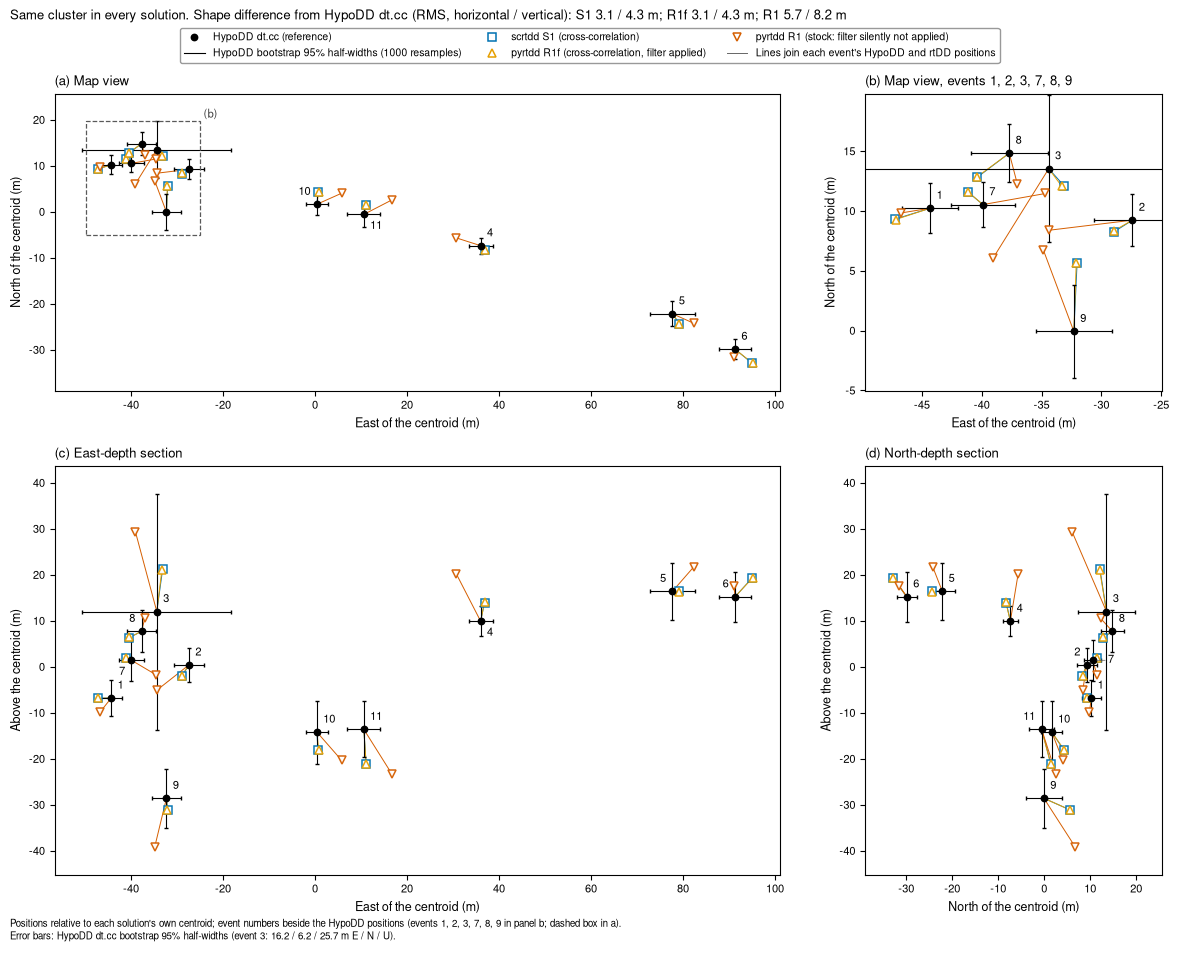

In [8]:
# Figure 1: map view and two vertical sections, each solution relative to its own centroid
REFP = hp.rel_centroid(pos("hypodd_dtcc"))
RP = {k: hp.rel_centroid(pos(k)) for k in F1_SOLUTIONS}
BX = BOOT_CC.rename(columns={"ex": "E", "ey": "N", "ez": "U"})
allp = pd.concat([REFP + BX, REFP - BX] + list(RP.values()))
LO = {c: float(allp[c].min()) - F1_PAD_M for c in "ENU"}
HI = {c: float(allp[c].max()) + F1_PAD_M for c in "ENU"}
SPAN = {c: HI[c] - LO[c] for c in "ENU"}
s_ = F1_IN_PER_M
ml_, mb_, gw_, gh_, mr_, mt_ = 0.75, 0.55, 0.85, 0.75, 0.15, 0.15       # margins and gaps (inches)
wE, wN, hN, hU = SPAN["E"] * s_, SPAN["N"] * s_, SPAN["N"] * s_, SPAN["U"] * s_
W, H = ml_ + wE + gw_ + wN + mr_, mb_ + hU + gh_ + hN + mt_
fig = plt.figure(figsize=(W, H))
ax_en = fig.add_axes([ml_ / W, (mb_ + hU + gh_) / H, wE / W, hN / H])
ax_eu = fig.add_axes([ml_ / W, mb_ / H, wE / W, hU / H])
ax_nu = fig.add_axes([(ml_ + wE + gw_) / W, mb_ / H, wN / W, hU / H])
ax_zm = fig.add_axes([(ml_ + wE + gw_) / W, (mb_ + hU + gh_) / H, wN / W, hN / H])
VIEWS = [(ax_en, "E", "N", "East of the centroid (m)", "North of the centroid (m)", "(a) Map view"),
         (ax_eu, "E", "U", "East of the centroid (m)", "Above the centroid (m)", "(c) East-depth section"),
         (ax_nu, "N", "U", "North of the centroid (m)", "Above the centroid (m)", "(d) North-depth section")]
def draw_cluster(ax, cx, cy, ms_scale=1.0):
    # HypoDD with error bars, the rtDD solutions, and the lines joining the same event
    for k in F1_SOLUTIONS:
        for e in EVENTS:
            ax.plot([REFP.loc[e, cx], RP[k].loc[e, cx]], [REFP.loc[e, cy], RP[k].loc[e, cy]], color=STYLE[k]["color"],
                    lw=0.7, zorder=2)
    ax.errorbar(REFP[cx], REFP[cy], xerr=BX[cx], yerr=BX[cy], fmt="none", ecolor="k", elinewidth=0.8, capsize=1.6,
                zorder=3)
    ax.plot(REFP[cx], REFP[cy], **mk("hypodd_dtcc", ms=4.5 * ms_scale, zorder=5))
    for k in F1_SOLUTIONS:
        ax.plot(RP[k][cx], RP[k][cy], **mk(k, ms=MS * ms_scale, zorder=4, alpha=0.95))


def label_events(ax, cx, cy, events, fontsize=8):
    # event numbers beside the HypoDD positions, away from markers, error bars and lines
    others = np.vstack([RP[k][[cx, cy]].to_numpy() for k in F1_SOLUTIONS] + [REFP.drop(index=events)[[cx, cy]].to_numpy()])
    segs = []
    for e in EVENTS:
        x0, y0 = REFP.loc[e, cx], REFP.loc[e, cy]
        segs += [(x0 - BX.loc[e, cx], y0, x0 + BX.loc[e, cx], y0), (x0, y0 - BX.loc[e, cy], x0, y0 + BX.loc[e, cy])]
        segs += [(x0, y0, RP[k].loc[e, cx], RP[k].loc[e, cy]) for k in F1_SOLUTIONS]
    hp.place_labels(ax, REFP.loc[events, cx].to_numpy(), REFP.loc[events, cy].to_numpy(), [str(e) for e in events],
                    avoid_xy=others, avoid_segments=segs, fontsize=fontsize, zorder=7)


for ax, cx, cy, xl, yl, tt in VIEWS:
    draw_cluster(ax, cx, cy)
    ax.set_xlim(LO[cx], HI[cx])
    ax.set_ylim(LO[cy], HI[cy])
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(xl)
    ax.set_ylabel(yl)
    ax.set_title(tt, loc="left")
# panel d: the crowded western group of the map view at a larger scale (equal east and north scales)
zp = pd.concat([REFP.loc[F1_ZOOM_EVENTS]] + [RP[k].loc[F1_ZOOM_EVENTS] for k in F1_SOLUTIONS])
ze0, ze1 = zp.E.min() - F1_ZOOM_PAD_M, zp.E.max() + F1_ZOOM_PAD_M
zn0, zn1 = zp.N.min() - F1_ZOOM_PAD_M, zp.N.max() + F1_ZOOM_PAD_M
if (ze1 - ze0) / (zn1 - zn0) > wN / hN:
    mid, half = 0.5 * (zn0 + zn1), 0.5 * (ze1 - ze0) * hN / wN
    zn0, zn1 = mid - half, mid + half
else:
    mid, half = 0.5 * (ze0 + ze1), 0.5 * (zn1 - zn0) * wN / hN
    ze0, ze1 = mid - half, mid + half
draw_cluster(ax_zm, "E", "N")
ax_zm.set_xlim(ze0, ze1)
ax_zm.set_ylim(zn0, zn1)
ax_zm.set_aspect("equal", adjustable="box")
ax_zm.set_xlabel("East of the centroid (m)")
ax_zm.set_ylabel("North of the centroid (m)")
ax_zm.set_title(f"(b) Map view, events {', '.join(str(e) for e in F1_ZOOM_EVENTS)}", loc="left")
ax_en.add_patch(Rectangle((ze0, zn0), ze1 - ze0, zn1 - zn0, facecolor="none", edgecolor="0.35", lw=0.9, ls="--", zorder=6))
ax_en.text(ze1, zn1, " (b)", ha="left", va="bottom", fontsize=8, color="0.25", zorder=7)
OUT_ZOOM = [e for e in EVENTS if e not in F1_ZOOM_EVENTS]
label_events(ax_en, "E", "N", OUT_ZOOM)
label_events(ax_zm, "E", "N", F1_ZOOM_EVENTS)
for ax, cx, cy, *_ in VIEWS[1:]:
    label_events(ax, cx, cy, EVENTS)
F1M = {k: met(k, "hypodd_dtcc") for k in F1_SOLUTIONS}
handles = [Line2D([], [], **mk("hypodd_dtcc", ms=4.5)), Line2D([], [], color="k", lw=0.8)] + [handle(k) for k in F1_SOLUTIONS] + \
          [Line2D([], [], color="0.4", lw=0.7)]
labels = [STYLE["hypodd_dtcc"]["label"], f"HypoDD bootstrap 95% half-widths ({N_BOOT} resamples)"] + \
         [STYLE[k]["label"] for k in F1_SOLUTIONS] + ["Lines join each event's HypoDD and rtDD positions"]
leg = hp.legend_above(fig, [ax_en, ax_zm, ax_eu, ax_nu], handles, labels, ncol=3, fontsize=7.5)
msg = ("Same cluster in every solution. Shape difference from HypoDD dt.cc (RMS, horizontal / vertical): "
       + "; ".join(f"{k} {F1M[k]['rms_h']:.1f} / {F1M[k]['rms_v']:.1f} m" for k in F1_SOLUTIONS))
hp.text_above(fig, [ax_en, ax_zm, ax_eu, ax_nu, leg], msg, fontsize=9.5)
note = (f"Positions relative to each solution's own centroid; event numbers beside the HypoDD positions (events "
        f"{', '.join(str(e) for e in F1_ZOOM_EVENTS)} in panel b; dashed box in a). Error bars: "
        f"HypoDD dt.cc bootstrap 95% half-widths (event {EV3}: " + " / ".join(f"{v:.1f}" for v in BOOT_CC.loc[EV3])
        + " m E / N / U).")
hp.text_below(fig, [ax_eu, ax_nu], textwrap.fill(note, 150), fontsize=7)
FIGS["1"] = hp.save_fig(fig, FIG_DIR, "02_1_cluster_map_sections", dpi=FIG_DPI)
plt.show()

## 3. Figure 2: each event's difference from HypoDD, with HypoDD's own error bars

**What it shows.** For every event, the difference between its position in an rtDD solution and in HypoDD (both
relative to their own centroids), split into east and north (horizontal) and up (vertical). The gray box around
zero is HypoDD's bootstrap 95% half-width for that event and direction. Left column: the cross-correlation runs
against HypoDD dt.cc (S1, R1f, stock R1, and S2 with rtDD's default solver). Right column: the catalog-only run S0
against HypoDD dt.ct, with dt.ct's own, much wider box.

**How to read the box.** HypoDD's bootstrap re-runs HypoDD from its own solution with resampled data and the same
settings. The box therefore says how much HypoDD's answer wobbles when its own data are shuffled: it measures only
HypoDD's own precision. A point inside the box means "as close to HypoDD as HypoDD is to itself", not "correct".

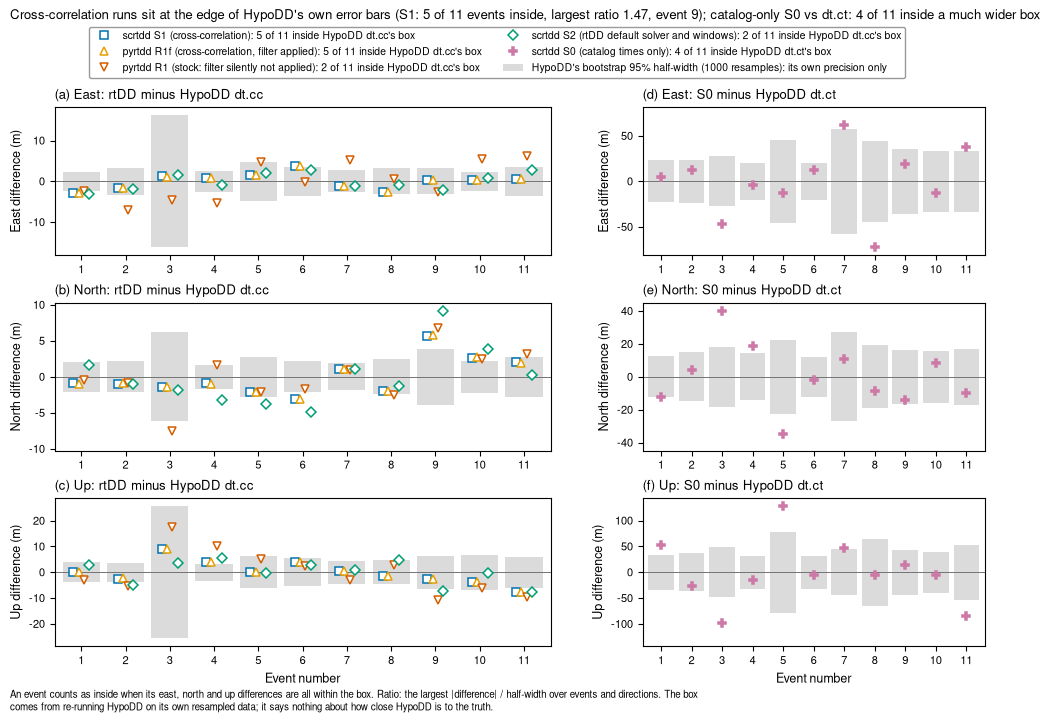

In [9]:
# Figure 2: per-event differences from HypoDD (east, north, up) with the bootstrap half-widths
COMP = [("dE", "ex", "East"), ("dN", "ey", "North"), ("dU", "ez", "Up")]
GROUPS = [("hypodd_dtcc", F2_XCORR, BOOT_CC, "HypoDD dt.cc"), ("hypodd_dtct", F2_CATALOG, BOOT_CT, "HypoDD dt.ct")]
nrow, ncol = len(COMP), len(GROUPS)
fig, axes = plt.subplots(nrow, ncol, figsize=(12.0, 2.2 * nrow + 0.4), squeeze=False,
                         gridspec_kw=dict(width_ratios=[1.45] + [1.0] * (ncol - 1), wspace=0.22, hspace=0.32))
xev = np.arange(1, N_EV + 1)
letters = iter("abcdefghijklmnop")
PANEL = {}
for j, (ref, sols, bx, refname) in enumerate(GROUPS):
    for i, (dc, bc, cname) in enumerate(COMP):
        ax = axes[i, j]
        for x_, e in zip(xev, EVENTS):
            hw = float(bx.loc[e, bc])
            ax.add_patch(Rectangle((x_ - 0.42, -hw), 0.84, 2 * hw, facecolor="0.86", edgecolor="none", zorder=1))
        ax.axhline(0.0, color="0.45", lw=0.7, zorder=2)
        offs = np.linspace(-F2_JITTER, F2_JITTER, len(sols)) if len(sols) > 1 else [0.0]
        for k, dx in zip(sols, offs):
            d = per_event(k, ref)
            ax.plot(xev + dx, d[dc].to_numpy(), **mk(k, ms=5.5, zorder=4))
        lim = 1.12 * max(float(bx[bc].max()), max(float(per_event(k, ref)[dc].abs().max()) for k in sols))
        ax.set_ylim(-lim, lim)
        ax.set_xlim(0.4, N_EV + 0.6)
        ax.set_xticks(xev)
        ax.set_xticklabels([str(e) for e in EVENTS])
        ax.set_ylabel(f"{cname} difference (m)")
        if i == nrow - 1:
            ax.set_xlabel("Event number")
        ax.set_title(f"({next(letters)}) {cname}: {'rtDD' if len(sols) > 1 else sols[0]} minus {refname}", loc="left")
        PANEL[(i, j)] = ax
F2M = {(k, ref): met(k, ref) for ref, sols, _, _ in GROUPS for k in sols}
handles, labels = [], []
for ref, sols, _, refname in GROUPS:
    for k in sols:
        m = F2M[(k, ref)]
        handles.append(handle(k, ms=5.5))
        labels.append(f"{STYLE[k]['label']}: {m['n_in']} of {N_EV} inside {refname}'s box")
handles.append(Patch(facecolor="0.86", edgecolor="none"))
labels.append(f"HypoDD's bootstrap 95% half-width ({N_BOOT} resamples): its own precision only")
leg = hp.legend_above(fig, axes, handles, labels, ncol=2, fontsize=7.5)
s1m, s0m = F2M[("S1", "hypodd_dtcc")], F2M[("S0", "hypodd_dtct")]
msg = (f"Cross-correlation runs sit at the edge of HypoDD's own error bars (S1: {s1m['n_in']} of {N_EV} events inside, "
       f"largest ratio {s1m['ratio']:.2f}, event {s1m['ratio_ev']}); catalog-only S0 vs dt.ct: {s0m['n_in']} of {N_EV} "
       f"inside a much wider box")
hp.text_above(fig, [leg] + list(axes.ravel()), msg, fontsize=9.5)
note = ("An event counts as inside when its east, north and up differences are all within the box. Ratio: the "
        "largest |difference| / half-width over events and directions. The box comes from re-running HypoDD on its "
        "own resampled data; it says nothing about how close HypoDD is to the truth.")
hp.text_below(fig, list(axes.ravel()), textwrap.fill(note, 175), fontsize=7)
FIGS["2"] = hp.save_fig(fig, FIG_DIR, "02_2_per_event_differences", dpi=FIG_DPI)
plt.show()

## 4. Figure 3: event-to-event distances

**What it shows.** Each dot is one pair of events: its distance in HypoDD (horizontal axis) against its distance in
the rtDD solution (vertical axis). Dots on the diagonal line mean the two programs agree on how far apart the two
events are, whatever the position or orientation of the cluster. (a) Cross-correlation: scrtdd S1 against HypoDD
dt.cc. (b) Catalog times only: scrtdd S0 against HypoDD dt.ct. The correlation r and the RMS difference are the values
stored in the comparison table (they are recomputed from the positions in section 1.1).

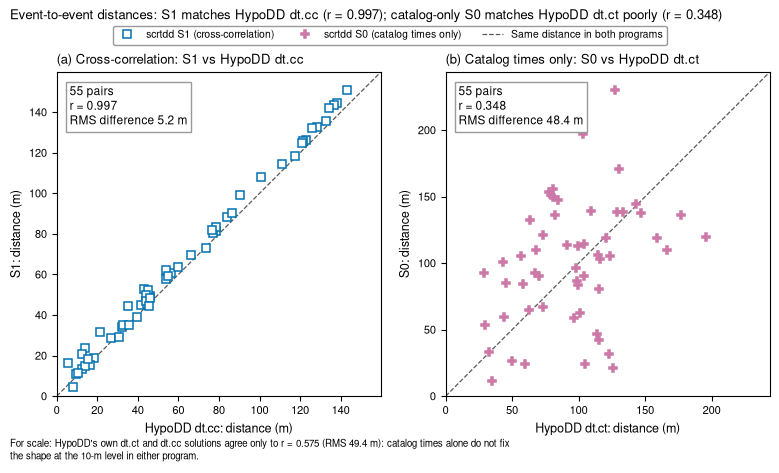

In [10]:
# Figure 3: inter-event distances, rtDD vs HypoDD
F3 = [("S1", "hypodd_dtcc", "(a) Cross-correlation: S1 vs HypoDD dt.cc"),
      ("S0", "hypodd_dtct", "(b) Catalog times only: S0 vs HypoDD dt.ct")]
fig, axes = plt.subplots(1, len(F3), figsize=(4.6 * len(F3), 4.7), squeeze=False)
axes = axes[0]
for ax, (k, ref, tt) in zip(axes, F3):
    dx, dy = hp.interevent(pos(ref).to_numpy()), hp.interevent(pos(k).to_numpy())
    lim = (0.0, 1.06 * max(dx.max(), dy.max()))
    ax.plot(lim, lim, color="0.35", lw=0.9, ls="--", zorder=1)
    ax.plot(dx, dy, **mk(k, ms=5.5, zorder=3))
    m = met(k, ref)
    ax.text(0.04, 0.96, f"{len(dx)} pairs\nr = {m['r']:.3f}\nRMS difference {m['rms_d']:.1f} m", transform=ax.transAxes,
            ha="left", va="top", fontsize=8.5, bbox=dict(boxstyle="square,pad=0.3", fc="white", ec="0.6"))
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.set_aspect("equal")
    ax.set_xlabel(f"{STYLE[ref]['label'].split(' (')[0]}: distance (m)")
    ax.set_ylabel(f"{k}: distance (m)")
    ax.set_title(tt, loc="left")
handles = [handle(k, ms=5.5) for k, _, _ in F3] + [Line2D([], [], color="0.35", lw=0.9, ls="--")]
labels = [STYLE[k]["label"] for k, _, _ in F3] + ["Same distance in both programs"]
leg = hp.legend_above(fig, axes, handles, labels, ncol=3, fontsize=7.5)
m1, m0 = met("S1", "hypodd_dtcc"), met("S0", "hypodd_dtct")
mref = met("hypodd_dtct", "hypodd_dtcc")
msg = (f"Event-to-event distances: S1 matches HypoDD dt.cc (r = {m1['r']:.3f}); catalog-only S0 matches HypoDD dt.ct "
       f"poorly (r = {m0['r']:.3f})")
hp.text_above(fig, [leg] + list(axes), msg, fontsize=9.5)
note = (f"For scale: HypoDD's own dt.ct and dt.cc solutions agree only to r = {mref['r']:.3f} "
        f"(RMS {mref['rms_d']:.1f} m): catalog times alone do not fix the shape at the 10-m level in either program.")
hp.text_below(fig, list(axes), textwrap.fill(note, 120), fontsize=7)
FIGS["3"] = hp.save_fig(fig, FIG_DIR, "02_3_interevent_distances", dpi=FIG_DPI)
plt.show()

## 5. Figure 4: are the cross-correlation measurements the same as the reference's?

**What it shows.** (a, b) For every event pair, station and phase where both scrtdd S1 and the reference passed
their CC threshold, the S1 differential time minus the reference dt.cc value, for P and S. The pairs are split by
whether HypoDD itself kept the reference value in its last iteration or threw it out as an outlier (HypoDD's
`hypoDD.res`). The horizontal axis is linear within ±5.5 ms (1-ms bins) and logarithmic beyond
(wider bins); the shaded band marks ±2 ms. The counts are on a logarithmic axis. pyrtdd R1f measures
the same lags as S1 (Figure 6), so its histogram is the same.
(c) How many measurements reach |CC| ≥ 0.7: the reference (positive CC only), scrtdd S1 (= R1f), scrtdd S2
(rtDD default windows) and stock pyrtdd R1. The hatched part counts negative correlations (mirror-image waveforms),
which rtDD accepts and the reference did not. The dashed line is the number of pairs measured.

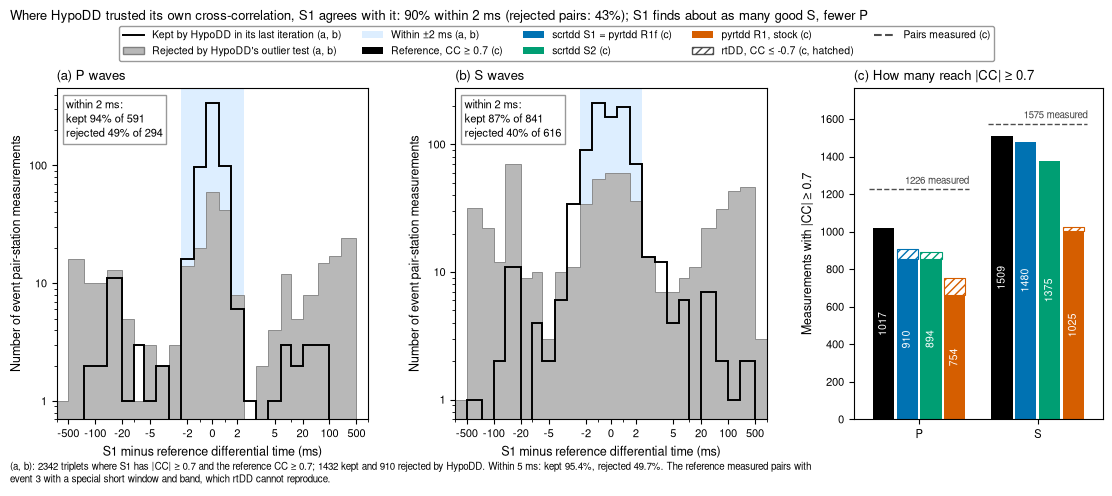

In [11]:
# Figure 4: S1 minus reference differential times (kept / rejected by HypoDD) and counts of |CC| >= CC_MIN
key = ["id1", "id2", "station", "phase"]
used = hp.normalize_pairs(pd.DataFrame({"id1": DT_USED.rtdd_id_1, "id2": DT_USED.rtdd_id_2, "station": DT_USED.station,
                                        "phase": DT_USED.phase, "dt_ref": DT_USED.dt_s,
                                        "kept": DT_USED.kept_in_final_iteration.astype(str).str.lower().eq("true")}),
                          flip_cols=("dt_ref",))
BOTH = TRIP_REF[TRIP_REF.valid & (TRIP_REF.cc.abs() >= CC_MIN)].merge(used, on=key)
BOTH["d_ms"] = (BOTH.dt_s - BOTH.dt_ref) * 1000.0
assert np.allclose(BOTH.d_ms, BOTH.diff_ms, atol=1e-6), "the triplet table's diff_ms is not S1 minus reference"
assert BOTH.d_ms.abs().max() < HIST_OUTER_EDGES_MS[-1], "a difference lies beyond the last histogram edge"
xr = SC_XREF[(SC_XREF.program == "scrtdd") & (SC_XREF.key == "S1")].iloc[0]
for lab, sub in (("kept_by_hypodd", BOTH[BOTH.kept]), ("rejected_by_hypodd", BOTH[~BOTH.kept])):
    fr = hp.grid_fractions(sub.d_ms, WITHIN_MS)
    CHECKS.append(hp.check_row(f"S1 pairs {lab}: count recomputed vs xcorr_vs_reference.csv", len(sub), xr[f"both_used_{lab}_n"], 0))
    for lim_ in WITHIN_MS:
        CHECKS.append(hp.check_row(f"S1 pairs {lab}: within {lim_} ms recomputed vs stored", fr[lim_],
                                   xr[f"both_used_{lab}_frac_within_{lim_}ms"], 1e-4))
# reference counts from the measured table
REFN = {ph: dict(measured=int((DT_MEAS.phase == ph).sum()), ok=int(((DT_MEAS.phase == ph) & (DT_MEAS.cc >= CC_MIN)).sum()))
        for ph in ("P", "S")}
r1f_sum = PY_SUM[(PY_SUM.short == "R1f") & (PY_SUM.reference == "hypodd_dtcc")].iloc[0]
for ph in ("P", "S"):
    CHECKS.append(hp.check_row(f"reference {ph}: CC >= {CC_MIN} in dtcc_measured.csv vs summary_metrics.csv",
                               REFN[ph]["ok"], r1f_sum[f"f_ref_n_cc07_{ph}"], 0))
    CHECKS.append(hp.check_row(f"reference {ph}: measured in dtcc_measured.csv vs summary_metrics.csv",
                               REFN[ph]["measured"], r1f_sum[f"f_ref_n_measured_{ph}"], 0))
CHECKS.append(hp.check_row(f"reference: CC >= {CC_MIN} in dtcc_measured.csv vs rows of dtcc_used.csv",
                           REFN["P"]["ok"] + REFN["S"]["ok"], len(DT_USED), 0))


def xc_counts(k):
    # |CC| >= CC_MIN counts of an rtDD run, split into positive and negative CC
    if k in SCRTDD:
        r = SC_XREF[(SC_XREF.program == "scrtdd") & (SC_XREF.key == k)].iloc[0]
    else:
        r = SC_XREF[(SC_XREF.program == "pyrtdd") & (SC_XREF.key == k)].iloc[0]
    return {ph: dict(measured=int(r[f"{ph}_attempted_valid"]), pos=int(r[f"{ph}_pos_cc_ge_0p7"]),
                     neg=int(r[f"{ph}_neg_cc_le_m0p7"]), ok=int(r[f"{ph}_abs_cc_ge_0p7"])) for ph in ("P", "S")}


XCN = {k: xc_counts(k) for k in sorted(set(F4_RUNS) | set(F5_RUNS))}


def count_bars(ax, runs):
    # |CC| >= CC_MIN counts per phase: the reference (black, CC >= CC_MIN) and rtDD runs (positive CC solid, negative
    # CC hatched); the number inside each bar is the total; the dashed line is the number of pairs measured
    bars = [None] + list(runs)
    width = 0.8 / len(bars)
    for gi, ph in enumerate(("P", "S")):
        meas = REFN[ph]["measured"]
        ax.plot([gi - 0.42, gi + 0.42], [meas] * 2, color="0.3", ls="--", lw=1.0, zorder=1)
        ax.text(gi + 0.42, meas + 15, f"{meas} measured", ha="right", va="bottom", fontsize=7, color="0.25")
        for bi, k in enumerate(bars):
            x_ = gi - 0.4 + width * (bi + 0.5)
            if k is None:
                p_, n_, col = REFN[ph]["ok"], 0, "k"
            else:
                p_, n_, col = XCN[k][ph]["pos"], XCN[k][ph]["neg"], STYLE[k]["color"]
            ax.bar(x_, p_, width * 0.9, color=col, zorder=2)
            if n_:
                ax.bar(x_, n_, width * 0.9, bottom=p_, facecolor="white", edgecolor=col, hatch="////", lw=0.8, zorder=2)
            ax.text(x_, 0.5 * p_, f"{p_ + n_}", rotation=90, ha="center", va="center", fontsize=7.5,
                    color=hp.text_color_on(col), zorder=3)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["P", "S"])
    ax.set_xlim(-0.55, 1.55)
    ax.set_ylim(0, 1.12 * max(REFN[ph]["measured"] for ph in ("P", "S")))
    ax.set_ylabel(f"Measurements with |CC| ≥ {CC_MIN:g}")

edges = np.r_[-np.array(HIST_OUTER_EDGES_MS[::-1]), np.arange(-HIST_INNER_MS + 0.5, HIST_INNER_MS - 0.4, 1.0),
              np.array(HIST_OUTER_EDGES_MS)]
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.3), gridspec_kw=dict(width_ratios=[1.25, 1.25, 1.0], wspace=0.3))
F4FR = {}
for ax, ph, tt in zip(axes[:2], ("P", "S"), ("(a) P waves", "(b) S waves")):
    sub = BOTH[BOTH.phase == ph]
    ax.axvspan(-WITHIN_MS[0] - 0.5, WITHIN_MS[0] + 0.5, color="#DDEEFF", zorder=0, lw=0)
    ax.hist(sub[~sub.kept].d_ms, bins=edges, histtype="stepfilled", color="0.72", edgecolor="0.5", lw=0.6, zorder=2)
    ax.hist(sub[sub.kept].d_ms, bins=edges, histtype="step", color="k", lw=1.4, zorder=3)
    ax.set_xscale("symlog", linthresh=HIST_LINTHRESH_MS, linscale=HIST_LINSCALE)
    ax.set_yscale("log")
    plain_log(ax)
    tk = [-500, -100, -20, -5, -2, 0, 2, 5, 20, 100, 500]
    ax.set_xticks(tk)
    ax.set_xticklabels([f"{t:d}" for t in tk])
    ax.set_xlim(edges[0], edges[-1])
    ax.set_ylim(0.7, None)
    ax.set_xlabel("S1 minus reference differential time (ms)")
    ax.set_ylabel("Number of event pair-station measurements")
    ax.set_title(tt, loc="left")
    fk, fr_ = hp.grid_fractions(sub[sub.kept].d_ms, WITHIN_MS), hp.grid_fractions(sub[~sub.kept].d_ms, WITHIN_MS)
    F4FR[ph] = dict(kept=fk, rej=fr_, n_kept=int(sub.kept.sum()), n_rej=int((~sub.kept).sum()))
    ax.text(0.03, 0.97, f"within {WITHIN_MS[0]} ms:\nkept {fk[WITHIN_MS[0]]:.0%} of {int(sub.kept.sum())}\n"
                        f"rejected {fr_[WITHIN_MS[0]]:.0%} of {int((~sub.kept).sum())}",
            transform=ax.transAxes, ha="left", va="top", fontsize=8, bbox=dict(boxstyle="square,pad=0.3", fc="white", ec="0.6"))
ax = axes[2]
count_bars(ax, F4_RUNS)
ax.set_title(f"(c) How many reach |CC| ≥ {CC_MIN:g}", loc="left")
handles = [Line2D([], [], color="k", lw=1.4), Patch(facecolor="0.72", edgecolor="0.5"), Patch(facecolor="#DDEEFF"),
           Patch(facecolor="k"), Patch(facecolor=STYLE["S1"]["color"]), Patch(facecolor=STYLE["S2"]["color"]),
           Patch(facecolor=STYLE["R1"]["color"]), Patch(facecolor="white", edgecolor="0.3", hatch="////"),
           Line2D([], [], color="0.3", ls="--")]
labels = ["Kept by HypoDD in its last iteration (a, b)", "Rejected by HypoDD's outlier test (a, b)",
          f"Within ±{WITHIN_MS[0]} ms (a, b)", f"Reference, CC ≥ {CC_MIN:g} (c)", "scrtdd S1 = pyrtdd R1f (c)",
          "scrtdd S2 (c)", "pyrtdd R1, stock (c)", f"rtDD, CC ≤ -{CC_MIN:g} (c, hatched)", "Pairs measured (c)"]
leg = hp.legend_above(fig, axes, handles, labels, ncol=5, fontsize=7.5)
kall = hp.grid_fractions(BOTH[BOTH.kept].d_ms, WITHIN_MS)
rall = hp.grid_fractions(BOTH[~BOTH.kept].d_ms, WITHIN_MS)
msg = (f"Where HypoDD trusted its own cross-correlation, S1 agrees with it: {kall[WITHIN_MS[0]]:.0%} within "
       f"{WITHIN_MS[0]} ms (rejected pairs: {rall[WITHIN_MS[0]]:.0%}); S1 finds about as many good S, fewer P")
hp.text_above(fig, [leg] + list(axes), msg, fontsize=9.5)
note = (f"(a, b): {len(BOTH)} triplets where S1 has |CC| ≥ {CC_MIN:g} and the reference CC ≥ {CC_MIN:g}; "
        f"{int(BOTH.kept.sum())} kept and {int((~BOTH.kept).sum())} rejected by HypoDD. Within {WITHIN_MS[1]} ms: kept "
        f"{kall[WITHIN_MS[1]]:.1%}, rejected {rall[WITHIN_MS[1]]:.1%}. The reference measured pairs with event {EV3} with "
        f"a special short window and band, which rtDD cannot reproduce.")
hp.text_below(fig, list(axes), textwrap.fill(note, 190), fontsize=7)
FIGS["4"] = hp.save_fig(fig, FIG_DIR, "02_4_cross_correlation_vs_reference", dpi=FIG_DPI)
plt.show()

## 6. Figure 5: the pyrtdd filter bug, made visible

**In two plain sentences.** libhdd (rtDD's C++ engine) asks the waveform loader to band-pass each trace *in place*,
but pyrtdd's pybind11 trampoline (`package/src/pyrtdd/hdd/proxy_ext.cpp`, lines 78-79,
printed below) hands the Python `filter()` a *copy* of the trace, so the filtered samples are thrown away and libhdd
correlates unfiltered waveforms whatever filter is requested. scrtdd's loader is C++ code that filters the trace
itself, so scrtdd is not affected.

**What the figure shows.** (a, b) The same two-event, one-station cross-correlation (events and station in the
check's input files) run with five different "filters": none, the requested band-pass, a drastic low-pass, a filter
that sets every sample to zero, and one that flips the sign. If the filter reached libhdd, the band-pass and low-pass
should change the result and the zeroing filter should make the correlation fail. All five give the same CC and lag.
(The sign flip is not a test: it flips both traces, which leaves their correlation unchanged.) (c) The effect on
the relocation: shape difference from HypoDD dt.cc for stock pyrtdd R1, pyrtdd with the filter really applied (R1f)
and scrtdd S1. (d) The number of good (|CC| ≥ 0.7) cross-correlation measurements for the same runs and the
reference.

In [12]:
# Figure 5, evidence 1: the filter() override in pyrtdd's trampoline, printed from the source file
with open(PROXY_EXT_CPP) as f:
    src = f.read().splitlines()
for n in range(PROXY_EXT_LINES[0] - 1, PROXY_EXT_LINES[1] + 1):
    print(f"{PROXY_EXT_CPP.split('/package/')[1]}:{n:3d}  {src[n - 1]}")
info = {k: hp.read_json(PY_RUN_INFO.format(run=RUNS[k])).get("filter_calls_received_by_proxy") for k in ("R1", "R2")}
print("filter() calls libhdd made to the stock proxy in the real runs (run_info.json):", info)

src/pyrtdd/hdd/proxy_ext.cpp: 77  
src/pyrtdd/hdd/proxy_ext.cpp: 78    void filter(Trace &trace, std::string const &filterStr) override {
src/pyrtdd/hdd/proxy_ext.cpp: 79      PYBIND11_OVERRIDE_PURE(void, Proxy, filter, trace, filterStr);
filter() calls libhdd made to the stock proxy in the real runs (run_info.json): {'R1': {'bandpass;freqmin=5;freqmax=20;corners=4 @ 1000 Hz': 1165}, 'R2': {'bandpass;freqmin=5;freqmax=20;corners=4 @ 1000 Hz': 1165}}


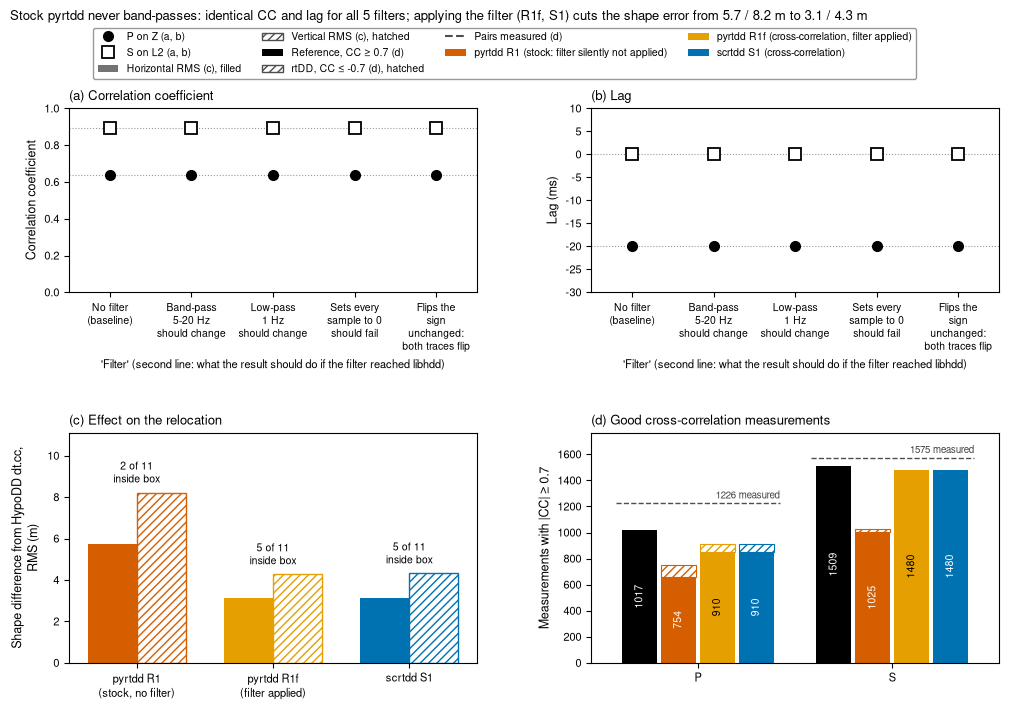

In [13]:
# Figure 5: five 'filters' give identical CC and lag; effect on the relocation and on the CC counts
CASES = list(FILTER_TEST.keys())
FT = {c: {r["phaseType"]: r for r in FILTER_TEST[c]} for c in CASES}
same = all(FT[c][ph]["coefficient"] == FT[CASES[0]][ph]["coefficient"] and FT[c][ph]["lag"] == FT[CASES[0]][ph]["lag"]
           and FT[c][ph]["valid"] for c in CASES for ph in ("P", "S"))
fig, axes = plt.subplots(2, 2, figsize=(12.0, 7.2), gridspec_kw=dict(hspace=0.68, wspace=0.28, height_ratios=[0.8, 1.0]))
xc_ = np.arange(len(CASES))
PH_MK = {"P": dict(marker="o", mfc="k", mec="k", ms=7, ls="none"), "S": dict(marker="s", mfc="white", mec="k", mew=1.3, ms=8, ls="none")}
for ax, fld, yl, tt, scale in ((axes[0, 0], "coefficient", "Correlation coefficient", "(a) Correlation coefficient", 1.0),
                               (axes[0, 1], "lag", "Lag (ms)", "(b) Lag", 1000.0)):
    for ph in ("P", "S"):
        v = np.array([FT[c][ph][fld] for c in CASES]) * scale
        ax.plot(xc_, v, **PH_MK[ph], zorder=3)
        ax.axhline(v[0], color="0.6", lw=0.8, ls=":", zorder=1)
    ax.set_xticks(xc_)
    ax.set_xticklabels([f"{F5_CASE_LABELS.get(c, c)}\n{F5_EXPECTED.get(c, '')}" for c in CASES], fontsize=7.5)
    ax.set_xlim(-0.5, len(CASES) - 0.5)
    ax.set_ylabel(yl)
    ax.set_xlabel("'Filter' (second line: what the result should do if the filter reached libhdd)", fontsize=8)
    ax.set_title(tt, loc="left")
lo_, hi_ = axes[0, 1].get_ylim()
axes[0, 1].set_ylim(min(lo_, -30), max(hi_, 10))
axes[0, 0].set_ylim(0.0, 1.0)
ax = axes[1, 0]
F5M = {k: met(k, "hypodd_dtcc") for k in F5_RUNS}
w_ = 0.36
for i, k in enumerate(F5_RUNS):
    ax.bar(i - w_ / 2, F5M[k]["rms_h"], w_, color=STYLE[k]["color"], zorder=2)
    ax.bar(i + w_ / 2, F5M[k]["rms_v"], w_, facecolor="white", edgecolor=STYLE[k]["color"], hatch="////", lw=1.0, zorder=2)
    ax.text(i, max(F5M[k]["rms_h"], F5M[k]["rms_v"]) + 0.3, f"{F5M[k]['n_in']} of {N_EV}\ninside box", ha="center",
            va="bottom", fontsize=7.5)
ax.set_xticks(range(len(F5_RUNS)))
ax.set_xticklabels([F5_TICK_LABELS.get(k, k) for k in F5_RUNS], fontsize=8)
ax.set_ylim(0, 1.35 * max(max(F5M[k]["rms_h"], F5M[k]["rms_v"]) for k in F5_RUNS))
ax.set_ylabel("Shape difference from HypoDD dt.cc,\nRMS (m)")
ax.set_title("(c) Effect on the relocation", loc="left")
ax = axes[1, 1]
count_bars(ax, F5_RUNS)
ax.set_title(f"(d) Good cross-correlation measurements", loc="left")
handles = [Line2D([], [], **PH_MK["P"]), Line2D([], [], **PH_MK["S"]), Patch(facecolor="0.45"),
           Patch(facecolor="white", edgecolor="0.3", hatch="////"), Patch(facecolor="k"),
           Patch(facecolor="white", edgecolor="0.3", hatch="////"), Line2D([], [], color="0.3", ls="--")]
labels = ["P on Z (a, b)", "S on L2 (a, b)", "Horizontal RMS (c), filled", "Vertical RMS (c), hatched",
          f"Reference, CC ≥ {CC_MIN:g} (d)", f"rtDD, CC ≤ -{CC_MIN:g} (d), hatched", "Pairs measured (d)"]
handles += [Patch(facecolor=STYLE[k]["color"]) for k in F5_RUNS]
labels += [STYLE[k]["label"] for k in F5_RUNS]
leg = hp.legend_above(fig, axes, handles, labels, ncol=4, fontsize=7.5)
msg = (f"Stock pyrtdd never band-passes: {'identical' if same else 'NOT identical'} CC and lag for all {len(CASES)} "
       f"filters; applying the filter (R1f, S1) cuts the shape error from {F5M['R1']['rms_h']:.1f} / {F5M['R1']['rms_v']:.1f} m "
       f"to {F5M['R1f']['rms_h']:.1f} / {F5M['R1f']['rms_v']:.1f} m")
hp.text_above(fig, [leg] + list(axes.ravel()), msg, fontsize=9.5)
FIGS["5"] = hp.save_fig(fig, FIG_DIR, "02_5_pyrtdd_filter_bug", dpi=FIG_DPI)
plt.show()

## 7. Figure 6: pyrtdd and scrtdd give the same numbers

**What it shows.** (a) The absolute position difference, scrtdd minus pyrtdd, event by event: catalog-only S0 minus
R0 (3-D distance), and cross-correlation S1 minus R1f (east, north, up). (b) The cross-correlation lags of S1 and R1f
compared measurement by measurement: how many are identical, differ by a few samples, or differ more. (c)
Single-event (real-time style) relocations: scrtdd's automatic-pick run SEa against pyrtdd's replica of scrtdd's two
steps R6tf, and scrtdd's manual-pick run SEm against pyrtdd's one-step R6f. Open symbols: the plain 3-D difference.
Filled symbols: after removing, event by event, the difference between the two multi-event catalogs the single-event
runs were relocated against (S1 minus R1f), which each single-event run inherits.

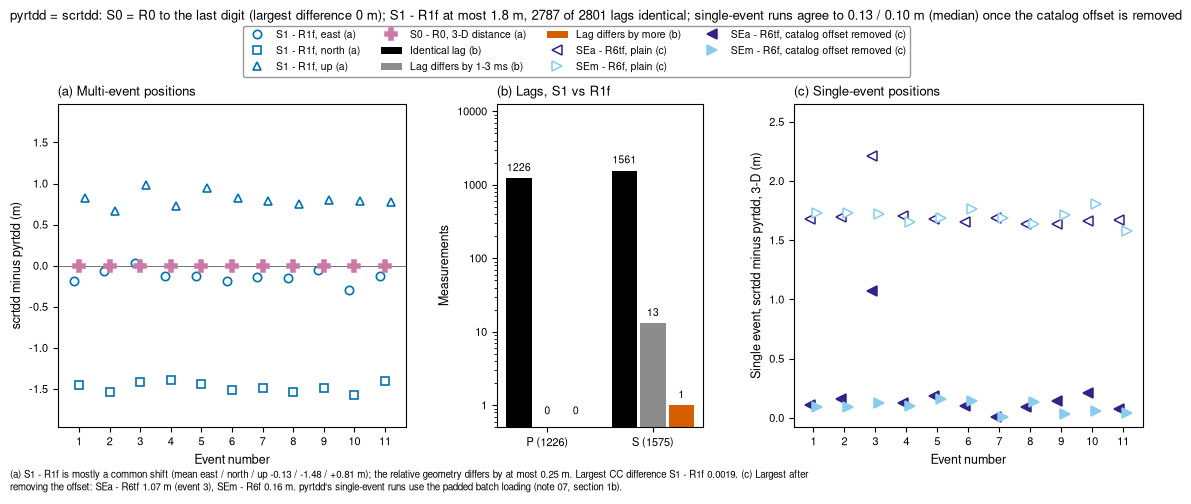

In [14]:
# Figure 6: scrtdd vs pyrtdd, multi-event and single-event
sp01 = SC_PY_PE[(SC_PY_PE.scrtdd == "S0") & (SC_PY_PE.py == "R0")].set_index("id").sort_index()
sp11 = SC_PY_PE[(SC_PY_PE.scrtdd == "S1") & (SC_PY_PE.py == "R1f")].set_index("id").sort_index()
sum01 = SC_PY_SUM[(SC_PY_SUM.scrtdd == "S0") & (SC_PY_SUM.py == "R0")].iloc[0]
sum11 = SC_PY_SUM[(SC_PY_SUM.scrtdd == "S1") & (SC_PY_SUM.py == "R1f")].iloc[0]
CHECKS.append(hp.check_row("S1 - R1f: mean east/north/up shift, per-event table vs summary (largest |difference|, m)",
                           np.abs(sp11[["dE_m", "dN_m", "dU_m"]].mean().to_numpy() -
                                  sum11[["centroid_diff_E_m", "centroid_diff_N_m", "centroid_diff_U_m"]].to_numpy(float)).max(),
                           0.0, 1e-3))
# lags, triplet by triplet
lagd = np.round((TRIP_S1R1F.lag_s_s - TRIP_S1R1F.lag_s_p) * 1000.0)
LAG = {ph: dict(same=int((lagd[TRIP_S1R1F.phase == ph] == 0).sum()),
                few=int(((lagd[TRIP_S1R1F.phase == ph].abs() >= 1) & (lagd[TRIP_S1R1F.phase == ph].abs() <= 3)).sum()),
                more=int((lagd[TRIP_S1R1F.phase == ph].abs() > 3).sum()), n=int((TRIP_S1R1F.phase == ph).sum()))
       for ph in ("P", "S")}
xs1 = SC_XSCPY[(SC_XSCPY.scrtdd == "S1") & (SC_XSCPY.py == "R1f")].iloc[0]
CHECKS.append(hp.check_row("S1 vs R1f: identical lags, triplets recomputed vs xcorr_scrtdd_vs_pyrtdd.csv",
                           LAG["P"]["same"] + LAG["S"]["same"], xs1.all_lag_identical, 0))
CHECKS.append(hp.check_row("S1 vs R1f: largest lag difference (ms), recomputed vs stored", float(lagd.abs().max()),
                           xs1.all_lag_diff_max_abs_ms, 0.5))
CC_DMAX = float((TRIP_S1R1F.cc_s - TRIP_S1R1F.cc_p).abs().max())
# single event: (SE - S1) - (R6 - R1f) removes the catalog offset; SE - R6 = that + (S1 - R1f)
SE_PAIRS = [("SEa", "R6tf"), ("SEm", "R6f")]
SEX = {}
for se_, r6 in SE_PAIRS:
    a = SE[SE["mode"] == se_].set_index("id").sort_index()[["final_dE_m", "final_dN_m", "final_dU_m"]].to_numpy()
    b = PY_PERVR[(PY_PERVR.b == "R1f") & (PY_PERVR.o == r6)].set_index("event_id").sort_index()[["dE_abs_m", "dN_abs_m", "dU_abs_m"]].to_numpy()
    off = a - b
    raw = off + sp11[["dE_m", "dN_m", "dU_m"]].to_numpy()
    SEX[se_] = dict(raw=np.linalg.norm(raw, axis=1), off=np.linalg.norm(off, axis=1), r6=r6)
    ctx = SE_CTX[(SE_CTX.run == se_) & (SE_CTX.vs == r6)].iloc[0]
    CHECKS.append(hp.check_row(f"{se_} vs {r6}: median 3-D, recomputed vs single_event_context.csv (m)",
                               np.median(SEX[se_]["raw"]), ctx.median_3d_m, 0.01))
    CHECKS.append(hp.check_row(f"{se_} vs {r6}: median 3-D after removing the catalog offset, recomputed vs stored (m)",
                               np.median(SEX[se_]["off"]), ctx.after_removing_catalog_offset_median_3d_m, 0.01))
    CHECKS.append(hp.check_row(f"{se_} vs {r6}: largest after removing the catalog offset, recomputed vs stored (m)",
                               SEX[se_]["off"].max(), ctx.after_removing_catalog_offset_max_3d_m, 0.01))
    SEX[se_]["ctx"] = ctx
fig, axes = plt.subplots(1, 3, figsize=(14.0, 4.2), gridspec_kw=dict(width_ratios=[1.35, 0.8, 1.35], wspace=0.3))
xev = np.arange(1, N_EV + 1)
ax = axes[0]
CMK = {"dE_m": ("o", "East"), "dN_m": ("s", "North"), "dU_m": ("^", "Up")}
for (c, (m_, lab)), dx in zip(CMK.items(), (-0.18, 0.0, 0.18)):
    ax.plot(xev + dx, sp11[c].to_numpy(), marker=m_, ls="none", mfc="white", mec=STYLE["S1"]["color"], mew=1.2, ms=6, zorder=3)
ax.plot(xev, sp01.d3_m.to_numpy(), **mk("S0", ms=8, zorder=4))
ax.axhline(0.0, color="0.45", lw=0.7, zorder=1)
ax.set_xticks(xev)
ax.set_xticklabels([str(e) for e in EVENTS])
ax.set_xlabel("Event number")
ax.set_ylabel("scrtdd minus pyrtdd (m)")
ax.set_title("(a) Multi-event positions", loc="left")
yl = 1.25 * float(sp11[["dE_m", "dN_m", "dU_m"]].abs().to_numpy().max())
ax.set_ylim(-yl, yl)
ax = axes[1]
for gi, ph in enumerate(("P", "S")):
    for bi, (fld, col) in enumerate((("same", "k"), ("few", "0.55"), ("more", "#D55E00"))):
        v = LAG[ph][fld]
        x_ = gi - 0.27 + 0.27 * bi
        if v > 0:
            ax.bar(x_, v, 0.24, color=col, zorder=2)
        ax.text(x_, max(v, 0.6) * 1.15, f"{v}", ha="center", va="bottom", fontsize=7.5)
ax.set_yscale("log")
plain_log(ax)
ax.set_ylim(0.5, 8 * max(LAG[ph]["n"] for ph in ("P", "S")))
ax.set_xticks([0, 1])
ax.set_xticklabels([f"P ({LAG['P']['n']})", f"S ({LAG['S']['n']})"])
ax.set_ylabel("Measurements")
ax.set_title("(b) Lags, S1 vs R1f", loc="left")
ax = axes[2]
for (se_, r6), dx in zip(SE_PAIRS, (-0.12, 0.12)):
    ax.plot(xev + dx, SEX[se_]["raw"], **mk(se_, ms=6.5, filled=False, zorder=3))
    ax.plot(xev + dx, SEX[se_]["off"], **mk(se_, ms=6.5, filled=True, zorder=4))
ax.set_xticks(xev)
ax.set_xticklabels([str(e) for e in EVENTS])
ax.set_xlabel("Event number")
ax.set_ylabel("Single event, scrtdd minus pyrtdd, 3-D (m)")
ax.set_ylim(-0.08, 1.2 * max(max(SEX[s]["raw"].max(), SEX[s]["off"].max()) for s in SEX))
ax.set_title("(c) Single-event positions", loc="left")
handles = [Line2D([], [], marker=m_, ls="none", mfc="white", mec=STYLE["S1"]["color"], mew=1.2, ms=6) for m_, _ in CMK.values()] + \
          [handle("S0", ms=8), Patch(facecolor="k"), Patch(facecolor="0.55"), Patch(facecolor="#D55E00")] + \
          [handle(s, ms=6.5, filled=False) for s, _ in SE_PAIRS] + [handle(s, ms=6.5, filled=True) for s, _ in SE_PAIRS]
labels = [f"S1 - R1f, {lab.lower()} (a)" for _, lab in CMK.values()] + ["S0 - R0, 3-D distance (a)",
          "Identical lag (b)", "Lag differs by 1-3 ms (b)", "Lag differs by more (b)"] + \
         [f"{s} - {r}, plain (c)" for s, r in SE_PAIRS] + [f"{s} - {r}, catalog offset removed (c)" for s, r in SE_PAIRS]
leg = hp.legend_above(fig, axes, handles, labels, ncol=4, fontsize=7.5)
nl = LAG["P"]["same"] + LAG["S"]["same"]
nt = LAG["P"]["n"] + LAG["S"]["n"]
msg = (f"pyrtdd = scrtdd: S0 = R0 to the last digit (largest difference {float(sum01.max_3d_diff_m):g} m); "
       f"S1 - R1f at most {float(sum11.max_3d_diff_m):.1f} m, {nl} of {nt} lags identical; single-event runs agree "
       f"to {np.median(SEX['SEa']['off']):.2f} / {np.median(SEX['SEm']['off']):.2f} m (median) once the catalog offset is removed")
hp.text_above(fig, [leg] + list(axes), msg, fontsize=9.5)
note = (f"(a) S1 - R1f is mostly a common shift (mean east / north / up {float(sum11.centroid_diff_E_m):+.2f} / "
        f"{float(sum11.centroid_diff_N_m):+.2f} / {float(sum11.centroid_diff_U_m):+.2f} m); the relative geometry differs by "
        f"at most {float(sum11.relative_geometry_max_3d_m):.2f} m. Largest CC difference S1 - R1f {CC_DMAX:.4f}. "
        f"(c) Largest after removing the offset: SEa - R6tf {SEX['SEa']['off'].max():.2f} m (event "
        f"{int(np.argmax(SEX['SEa']['off'])) + 1}), SEm - R6f {SEX['SEm']['off'].max():.2f} m. pyrtdd's single-event "
        f"runs use the padded batch loading (note 07, section 1b).")
hp.text_below(fig, list(axes), textwrap.fill(note, 200), fontsize=7)
FIGS["6"] = hp.save_fig(fig, FIG_DIR, "02_6_pyrtdd_equals_scrtdd", dpi=FIG_DPI)
plt.show()

## 8. Figure 7: the cluster keeps its shape, but its absolute position slides

**What it shows.** A diagnostic re-run of three pyrtdd runs (catalog only R0, stock R1, filtered R1f) with the same
data and the same cross-correlation results, changing only the number of iterations or the damping
(`diag_centroid_drift.csv`). These runs use no absolute-location equations (absLocConstraint 0), so only the damping
holds the cluster in place. (a) How far the cluster centroid has moved from its start (3-D), against the number of
iterations, at rtDD's default damping. (b) The cluster *shape* difference from HypoDD dt.cc (RMS, horizontal solid,
vertical dashed) against the number of iterations: once it has settled it stays put while the centroid keeps moving.
(c, d) The same two quantities after 20 iterations, against the damping. How much each run's shape differs from its
own final shape (20 iterations, default damping) is given in the note below the figure. The recommendation tested: damping ≥ 0.1, or
absLocConstraint > 0.

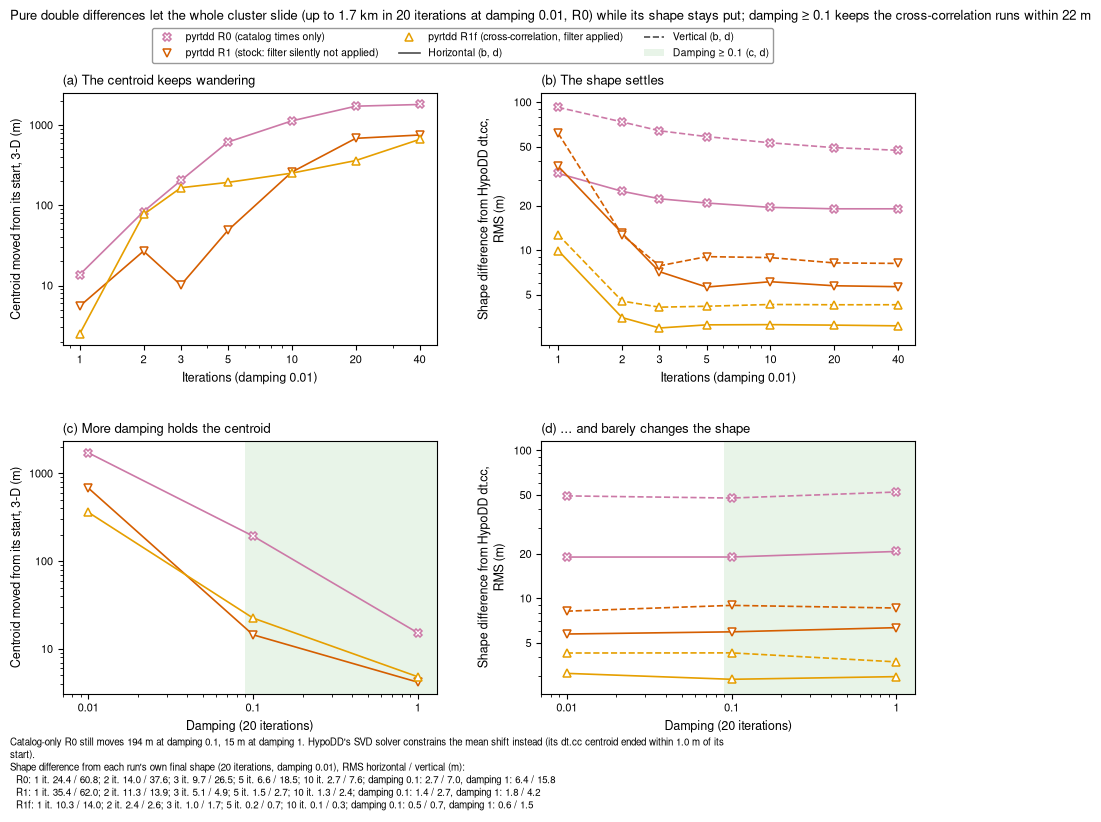

In [15]:
# Figure 7: centroid drift and shape settling, against iterations and damping
DRIFT["move_3d"] = np.sqrt(DRIFT.centroid_minus_start_e_m ** 2 + DRIFT.centroid_minus_start_n_m ** 2 + DRIFT.centroid_minus_start_u_m ** 2)
D_BASES = list(dict.fromkeys(DRIFT.b))
DAMP0 = float(DRIFT.dampingFactor.min())
IT0 = 20
CHECKS.extend(hp.check_row(f"drift table: {b} at {IT0} iterations, damping {DAMP0:g}: shape vs dt.cc (H) vs summary_metrics.csv",
                           DRIFT[(DRIFT.b == b) & (DRIFT.algoIterations == IT0) & (DRIFT.dampingFactor == DAMP0)].a_rel_rms_h_m.iloc[0],
                           met(b, "hypodd_dtcc")["rms_h"], TOL_METRIC_M) for b in D_BASES)
fig, axes = plt.subplots(2, 2, figsize=(11.0, 7.8), gridspec_kw=dict(hspace=0.38, wspace=0.28))
for b in D_BASES:
    it = DRIFT[(DRIFT.b == b) & (DRIFT.dampingFactor == DAMP0)].sort_values("algoIterations")
    dm = DRIFT[(DRIFT.b == b) & (DRIFT.algoIterations == IT0)].sort_values("dampingFactor")
    c = STYLE[b]["color"]
    axes[0, 0].plot(it.algoIterations, it.move_3d, color=c, lw=1.2, **{k: v for k, v in mk(b).items() if k not in ("ls", "color")})
    axes[1, 0].plot(dm.dampingFactor, dm.move_3d, color=c, lw=1.2, **{k: v for k, v in mk(b).items() if k not in ("ls", "color")})
    for ax, d in ((axes[0, 1], it), (axes[1, 1], dm)):
        xcol = "algoIterations" if d is it else "dampingFactor"
        ax.plot(d[xcol], d.a_rel_rms_h_m, color=c, lw=1.2, **{k: v for k, v in mk(b).items() if k not in ("ls", "color")})
        ax.plot(d[xcol], d.a_rel_rms_v_m, color=c, lw=1.2, ls="--", **{k: v for k, v in mk(b, filled=False).items() if k not in ("ls", "color")})
for ax in axes[0]:
    ax.set_xscale("log")
    xt = sorted(DRIFT.algoIterations.unique())
    ax.set_xticks(xt)
    ax.set_xticklabels([str(int(v)) for v in xt])
    ax.set_xlabel(f"Iterations (damping {DAMP0:g})")
for ax in axes[1]:
    ax.set_xscale("log")
    xt = sorted(DRIFT.dampingFactor.unique())
    ax.set_xticks(xt)
    ax.set_xticklabels([f"{v:g}" for v in xt])
    ax.set_xlabel(f"Damping ({IT0} iterations)")
    ax.axvspan(RECOMMENDED_MIN_DAMPING * 0.9, max(xt) * 1.3, color="#E8F4E8", zorder=0, lw=0)
    ax.set_xlim(min(xt) * 0.7, max(xt) * 1.3)
for ax in axes[:, 0]:
    ax.set_yscale("log")
    plain_log(ax)
    ax.set_ylabel("Centroid moved from its start, 3-D (m)")
ylo = 0.8 * float(DRIFT[["a_rel_rms_h_m", "a_rel_rms_v_m"]].to_numpy().min())
yhi = 1.25 * float(DRIFT[["a_rel_rms_h_m", "a_rel_rms_v_m"]].to_numpy().max())
for ax in axes[:, 1]:
    ax.set_yscale("log")
    ax.set_ylim(ylo, yhi)
    ax.set_ylabel("Shape difference from HypoDD dt.cc,\nRMS (m)")
    ax.set_yticks([v for v in (1, 2, 5, 10, 20, 50, 100) if ylo <= v <= yhi])
    ax.set_yticklabels([f"{v:g}" for v in (1, 2, 5, 10, 20, 50, 100) if ylo <= v <= yhi])
axes[0, 0].set_title("(a) The centroid keeps wandering", loc="left")
axes[0, 1].set_title("(b) The shape settles", loc="left")
axes[1, 0].set_title("(c) More damping holds the centroid", loc="left")
axes[1, 1].set_title("(d) ... and barely changes the shape", loc="left")
handles = [handle(b) for b in D_BASES] + [Line2D([], [], color="0.3", lw=1.2), Line2D([], [], color="0.3", lw=1.2, ls="--"),
                                          Patch(facecolor="#E8F4E8")]
labels = [STYLE[b]["label"] for b in D_BASES] + ["Horizontal (b, d)", "Vertical (b, d)",
                                                 f"Damping ≥ {RECOMMENDED_MIN_DAMPING:g} (c, d)"]
leg = hp.legend_above(fig, axes, handles, labels, ncol=3, fontsize=7.5)
mv = DRIFT.set_index(["b", "algoIterations", "dampingFactor"]).move_3d
max20 = max(float(mv.loc[(b, IT0, DAMP0)]) for b in D_BASES)
bmax = max(D_BASES, key=lambda b: float(mv.loc[(b, IT0, DAMP0)]))
xc_bases = [b for b in D_BASES if b != "R0"]
hold = DRIFT[(DRIFT.algoIterations == IT0) & (DRIFT.dampingFactor >= RECOMMENDED_MIN_DAMPING)]
msg = (f"Pure double differences let the whole cluster slide (up to {max20 / 1000.0:.1f} km in {IT0} iterations at damping "
       f"{DAMP0:g}, {bmax}) while its shape stays put; damping ≥ {RECOMMENDED_MIN_DAMPING:g} keeps the cross-correlation runs "
       f"within {hold[hold.b.isin(xc_bases)].move_3d.max():.0f} m")
hp.text_above(fig, [leg] + list(axes.ravel()), msg, fontsize=9.5)
r0h = hold[hold.b == "R0"].set_index("dampingFactor").move_3d
own = DRIFT.set_index(["b", "algoIterations", "dampingFactor"])[["shape_vs_base_rms_h_m", "shape_vs_base_rms_v_m"]]
its_ = [i for i in sorted(DRIFT.algoIterations.unique()) if i < IT0]
SETTLE = {b: "; ".join(f"{int(i)} it. {own.loc[(b, i, DAMP0)].iloc[0]:.1f} / {own.loc[(b, i, DAMP0)].iloc[1]:.1f}" for i in its_)
          for b in D_BASES}
DAMPCH = {b: ", ".join(f"damping {d:g}: {own.loc[(b, IT0, d)].iloc[0]:.1f} / {own.loc[(b, IT0, d)].iloc[1]:.1f}"
                       for d in sorted(DRIFT.dampingFactor.unique()) if d != DAMP0) for b in D_BASES}
note = (f"Catalog-only R0 still moves {', '.join(f'{v:.0f} m at damping {d:g}' for d, v in r0h.items())}. HypoDD's "
        f"SVD solver constrains the mean shift instead (its dt.cc centroid ended within "
        f"{float(np.linalg.norm(PY_AN['hypodd_log_final_centroid_shift_x_y_zdown_t_m_ms']['hypodd_dtcc'][:3])):.1f} m of its start).")
note = textwrap.fill(note, 175) + (f"\nShape difference from each run's own final shape ({IT0} iterations, damping {DAMP0:g}), "
                                    "RMS horizontal / vertical (m):\n" + "\n".join(f"  {b}: {SETTLE[b]}; {DAMPCH[b]}" for b in D_BASES))
hp.text_below(fig, list(axes.ravel()), note, fontsize=7)
FIGS["7"] = hp.save_fig(fig, FIG_DIR, "02_7_centroid_drift", dpi=FIG_DPI)
plt.show()

## 9. Figure 8: real-time style (single-event) relocation

**What it shows.** Each event in turn was removed from a multi-event catalog and relocated alone against all the
others, as rtDD would relocate a new event in real time. The figure shows how far each single-event position lies from
the same event's multi-event position in the catalog it was relocated against (scrtdd SEa and SEm against S1; pyrtdd
R6f and R6tf against R1f). (a) The 3-D distance per event on a logarithmic axis; for context the gray symbols show
where scrtdd's runs started (the HYPOINVERSE location) and where its first, catalog-only step ended. (b) A zoom:
horizontal distance against vertical offset, within ±2.5 m; points outside are listed in the panel.

**A caveat.** The background positions come from multi-event runs that *included* the left-out event, so this
is not a fully independent test.

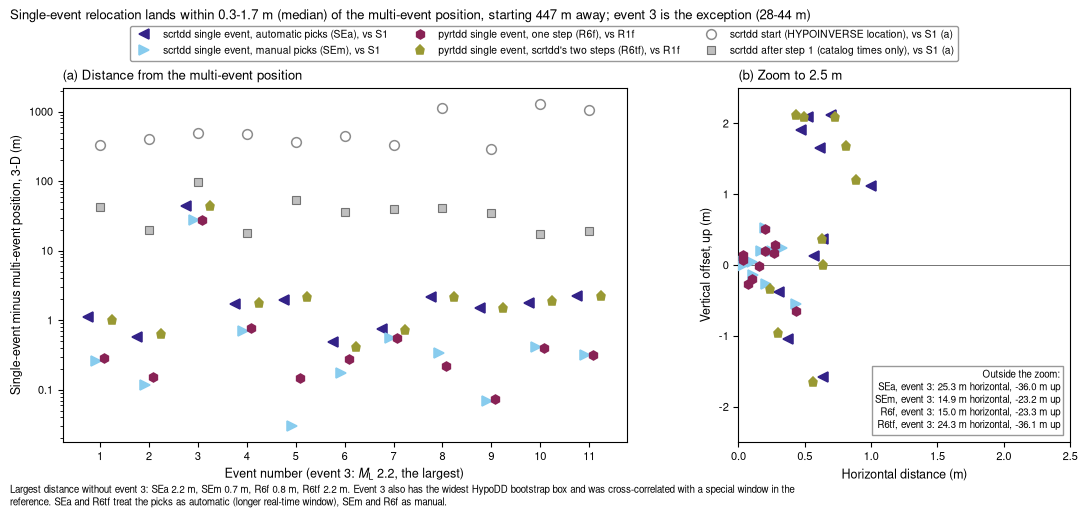

In [16]:
# Figure 8: single-event leave-one-out positions vs the multi-event positions of the same catalog
SE_RUNS = {"SEa": "S1", "SEm": "S1", "R6f": "R1f", "R6tf": "R1f"}
SED = {}
for k, base in SE_RUNS.items():
    if k in ("SEa", "SEm"):
        d = SE[SE["mode"] == k].set_index("id").sort_index()
        SED[k] = pd.DataFrame({"dE": d.final_dE_m, "dN": d.final_dN_m, "dU": d.final_dU_m, "d3": d.final_d3_m})
    else:
        d = PY_PERVR[(PY_PERVR.b == base) & (PY_PERVR.o == k)].set_index("event_id").sort_index()
        SED[k] = pd.DataFrame({"dE": d.dE_abs_m, "dN": d.dN_abs_m, "dU": d.dU_abs_m, "d3": d.d3D_abs_m})
    SED[k]["dH"] = np.hypot(SED[k].dE, SED[k].dN)
    ctx = SE_CTX[(SE_CTX.run == k) & (SE_CTX.vs == base)].iloc[0]
    CHECKS.append(hp.check_row(f"{k} vs {base}: median 3-D per-event table vs single_event_context.csv (m)",
                               SED[k].d3.median(), ctx.median_3d_m, 0.01))
CTXS = SE[SE["mode"] == "SEa"].set_index("id").sort_index()
assert np.allclose(CTXS.step1_d3_m, SE[SE["mode"] == "SEm"].set_index("id").sort_index().step1_d3_m), "step 1 differs"
fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.6), gridspec_kw=dict(width_ratios=[1.7, 1.0], wspace=0.25))
ax = axes[0]
xev = np.arange(1, N_EV + 1)
ax.plot(xev, CTXS.start_d3_m.to_numpy(), marker="o", ls="none", mfc="white", mec="0.55", ms=7, mew=1.1, zorder=2)
ax.plot(xev, CTXS.step1_d3_m.to_numpy(), marker="s", ls="none", mfc="0.75", mec="0.45", ms=6, mew=0.8, zorder=2)
for k, dx in zip(SE_RUNS, np.linspace(-0.24, 0.24, len(SE_RUNS))):
    ax.plot(xev + dx, SED[k].d3.to_numpy(), **mk(k, ms=6.5, zorder=4))
ax.set_yscale("log")
plain_log(ax)
ax.set_xticks(xev)
ax.set_xticklabels([f"{e}" for e in EVENTS])
ax.set_xlabel(f"Event number (event {EV3}: {ML} {EVMAP.kma_ml.loc[EV3]:.1f}, the largest)")
ax.set_ylabel("Single-event minus multi-event position, 3-D (m)")
ax.set_title("(a) Distance from the multi-event position", loc="left")
ax = axes[1]
far = []
for k in SE_RUNS:
    d = SED[k]
    inside = (d.dH <= F8_ZOOM_M) & (d.dU.abs() <= F8_ZOOM_M)
    ax.plot(d.dH[inside], d.dU[inside], **mk(k, ms=6.5, zorder=4))
    for e in d.index[~inside]:
        far.append(f"{k}, event {e}: {d.loc[e, 'dH']:.1f} m horizontal, {d.loc[e, 'dU']:+.1f} m up")
ax.axhline(0.0, color="0.45", lw=0.7, zorder=1)
ax.set_xlim(0, F8_ZOOM_M)
ax.set_ylim(-F8_ZOOM_M, F8_ZOOM_M)
ax.set_xlabel("Horizontal distance (m)")
ax.set_ylabel("Vertical offset, up (m)")
ax.set_title(f"(b) Zoom to {F8_ZOOM_M:g} m", loc="left")
ax.text(0.97, 0.03, "Outside the zoom:\n" + "\n".join(far), transform=ax.transAxes, ha="right", va="bottom", fontsize=7,
        bbox=dict(boxstyle="square,pad=0.3", fc="white", ec="0.6"))
handles = [handle(k, ms=6.5) for k in SE_RUNS] + [
    Line2D([], [], marker="o", ls="none", mfc="white", mec="0.55", ms=7, mew=1.1),
    Line2D([], [], marker="s", ls="none", mfc="0.75", mec="0.45", ms=6, mew=0.8)]
labels = [f"{STYLE[k]['label']}, vs {SE_RUNS[k]}" for k in SE_RUNS] + ["scrtdd start (HYPOINVERSE location), vs S1 (a)",
                                                                      "scrtdd after step 1 (catalog times only), vs S1 (a)"]
leg = hp.legend_above(fig, axes, handles, labels, ncol=3, fontsize=7.5)
med = {k: SED[k].d3.median() for k in SE_RUNS}
ev3 = {k: SED[k].d3.loc[EV3] for k in SE_RUNS}
others = {k: SED[k].d3.drop(EV3).max() for k in SE_RUNS}
msg = (f"Single-event relocation lands within {min(med.values()):.1f}-{max(med.values()):.1f} m (median) of the "
       f"multi-event position, starting {CTXS.start_d3_m.median():.0f} m away; event {EV3} is the exception "
       f"({min(ev3.values()):.0f}-{max(ev3.values()):.0f} m)")
hp.text_above(fig, [leg] + list(axes), msg, fontsize=9.5)
note = (f"Largest distance without event {EV3}: " + ", ".join(f"{k} {others[k]:.1f} m" for k in SE_RUNS) + ". "
        f"Event {EV3} also has the widest HypoDD bootstrap box and was cross-correlated with a special window in the "
        f"reference. SEa and R6tf treat the picks as automatic (longer real-time window), SEm and R6f as manual.")
hp.text_below(fig, list(axes), textwrap.fill(note, 190), fontsize=7)
FIGS["8"] = hp.save_fig(fig, FIG_DIR, "02_8_single_event", dpi=FIG_DPI)
plt.show()

## 10. Figure 9: which settings matter

**What it shows.** For each sensitivity test, how much the cluster *shape* changes when one setting is changed
(RMS of the shape difference between the two runs, horizontal and vertical, in meters, on a logarithmic axis). The
pairs come from `run_vs_run_metrics.csv` (pyrtdd) and `run_vs_run.csv` (scrtdd). For scale, the shaded band spans
HypoDD's own bootstrap 95% half-widths for the well-constrained events, i.e. all but the special event (its precision), and the dotted lines
mark how far HypoDD's own catalog-only and cross-correlation solutions are apart.

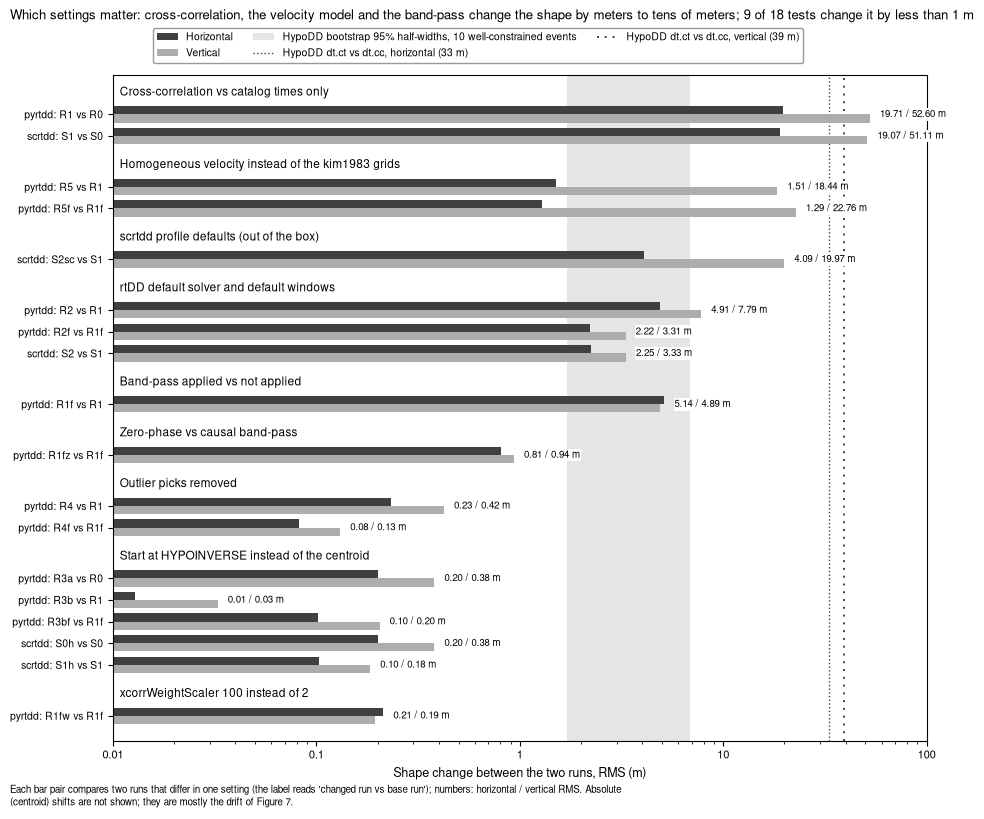

In [17]:
# Figure 9: shape change for each sensitivity pair
def rvr(tool, base, other):
    if tool == "pyrtdd":
        r = PY_RVR[(PY_RVR.b == base) & (PY_RVR.o == other)].iloc[0]
        return float(r.a_rel_rms_h_m), float(r.a_rel_rms_v_m)
    r = SC_RVR[(SC_RVR.base == base) & (SC_RVR.other == other)]
    if len(r):
        r = r.iloc[0]
    else:
        r = SC_RVR[(SC_RVR.base == other) & (SC_RVR.other == base)].iloc[0]
    return float(r.rms_h_m), float(r.rms_v_m)


def opt_value(run, path):
    o = hp.read_json(PY_OPTIONS.format(run=RUNS[run]))
    for p in path.split("."):
        o = o[p]
    return o


ROWS9 = []
for cat, items in F9_ITEMS:
    if cat == "xcorrWeightScaler":
        b_, o_ = items[0][1], items[0][2]
        cat = (f"xcorrWeightScaler {opt_value(o_, 'SolverOptions.xcorrWeightScaler'):g} instead of "
               f"{opt_value(b_, 'SolverOptions.xcorrWeightScaler'):g}")
    for tool, b_, o_ in items:
        h_, v_ = rvr(tool, b_, o_)
        ROWS9.append(dict(category=cat, tool=tool, base=b_, other=o_, rms_h=h_, rms_v=v_))
R9 = pd.DataFrame(ROWS9)
order = R9.groupby("category", sort=False)[["rms_h", "rms_v"]].max().max(axis=1).sort_values(ascending=False).index
ypos, yl_, cat_y = [], [], []
y = 0.0
for cat in order:
    sub = R9[R9.category == cat]
    cat_y.append((y, cat))
    y += 1.0
    for _, r in sub.iterrows():
        ypos.append(y)
        yl_.append(f"{r.tool}: {r.other} vs {r.base}")
        y += 1.0
    y += 0.35
R9o = pd.concat([R9[R9.category == c] for c in order]).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10.5, 0.26 * y + 0.8))
lo_b = float(BOOT_CC.loc[WELL, ["ex", "ey", "ez"]].to_numpy().min())
hi_b = float(BOOT_CC.loc[WELL, ["ex", "ey", "ez"]].to_numpy().max())
ax.axvspan(lo_b, hi_b, color="#E5E5E5", zorder=0, lw=0)
mref = met("hypodd_dtct", "hypodd_dtcc")
ax.axvline(mref["rms_h"], color="0.25", ls=":", lw=1.0, zorder=1)
ax.axvline(mref["rms_v"], color="0.25", ls=(0, (1, 3)), lw=1.4, zorder=1)
bh = 0.38
for yy, (_, r) in zip(ypos, R9o.iterrows()):
    ax.barh(yy - bh / 2, max(r.rms_h - F9_XLIM_M[0], 0.0), bh, left=F9_XLIM_M[0], color="0.25", zorder=2)
    ax.barh(yy + bh / 2, max(r.rms_v - F9_XLIM_M[0], 0.0), bh, left=F9_XLIM_M[0], color="0.68", zorder=2)
    ax.text(max(r.rms_h, r.rms_v) * 1.12, yy, f"{r.rms_h:.2f} / {r.rms_v:.2f} m", va="center", ha="left", fontsize=7,
            zorder=5, bbox=dict(boxstyle="square,pad=0.1", fc="white", ec="none"))
for yy, cat in cat_y:
    ax.text(F9_XLIM_M[0] * 1.08, yy, cat, va="center", ha="left", fontsize=8.5, color="k")
ax.set_xscale("log")
ax.set_xlim(*F9_XLIM_M)
xt9 = [v for v in (0.01, 0.1, 1.0, 10.0, 100.0) if F9_XLIM_M[0] <= v <= F9_XLIM_M[1]]
ax.set_xticks(xt9)
ax.set_xticklabels([f"{v:g}" for v in xt9])
ax.set_ylim(y - 0.2, -0.8)
ax.set_yticks(ypos)
ax.set_yticklabels(yl_, fontsize=7.5)
ax.set_xlabel("Shape change between the two runs, RMS (m)")
handles = [Patch(facecolor="0.25"), Patch(facecolor="0.68"), Patch(facecolor="#E5E5E5"),
           Line2D([], [], color="0.25", ls=":", lw=1.0), Line2D([], [], color="0.25", ls=(0, (1, 3)), lw=1.4)]
labels = ["Horizontal", "Vertical", f"HypoDD bootstrap 95% half-widths, {len(WELL)} well-constrained events",
          f"HypoDD dt.ct vs dt.cc, horizontal ({mref['rms_h']:.0f} m)", f"HypoDD dt.ct vs dt.cc, vertical ({mref['rms_v']:.0f} m)"]
leg = hp.legend_above(fig, ax, handles, labels, ncol=3, fontsize=7.5)
top = R9o.iloc[0]
small = R9o[R9o[["rms_h", "rms_v"]].max(axis=1) < 1.0]
msg = (f"Which settings matter: cross-correlation, the velocity model and the band-pass change the shape by meters to "
       f"tens of meters; {len(small)} of {len(R9o)} tests change it by less than 1 m")
hp.text_above(fig, [leg, ax], msg, fontsize=9.5)
note = ("Each bar pair compares two runs that differ in one setting (the label reads 'changed run vs base run'); "
        "numbers: horizontal / vertical RMS. Absolute (centroid) shifts are not shown; they are mostly the drift of Figure 7.")
hp.text_below(fig, [ax], textwrap.fill(note, 150), fontsize=7)
FIGS["9"] = hp.save_fig(fig, FIG_DIR, "02_9_settings_that_matter", dpi=FIG_DPI)
plt.show()

## 11. Comprehensive summary

First the result of the cross-file consistency checks, then the headline numbers, the take-home messages and the
caveats. Every number in this section is formatted from the variables above; none is typed in.

In [18]:
# 11. consistency checks: every check of sections 1.1 and of the figure cells
CHK = pd.DataFrame(CHECKS)
BAD = CHK[~CHK.Consistent]
print(f"{len(CHK)} cross-file checks; {int(CHK.Consistent.sum())} consistent, {len(BAD)} not")
with pd.option_context("display.max_colwidth", 130):
    display(hp.fmt_frame(CHK, 4))
if len(BAD):
    display(Markdown("**Inconsistent between files:**\n\n" + "\n".join(f"- {r.Check}: {r['Value A']:.4g} vs {r['Value B']:.4g}"
                                                                        for _, r in BAD.iterrows())))

94 cross-file checks; 94 consistent, 0 not


,Check,Value A,Value B,|A - B|,Tolerance,Consistent
0,"positions of hypodd_dtcc: scrtdd table vs pyrtdd table, largest |difference| (m)",0.0270,0.0000,0.0270,0.0600,True
1,"positions of hypodd_dtct: scrtdd table vs pyrtdd table, largest |difference| (m)",0.0270,0.0000,0.0270,0.0600,True
2,"positions of R0: scrtdd table vs pyrtdd table, largest |difference| (m)",0.0480,0.0000,0.0480,0.0600,True
3,"positions of R1: scrtdd table vs pyrtdd table, largest |difference| (m)",0.0470,0.0000,0.0470,0.0600,True
4,"positions of R1f: scrtdd table vs pyrtdd table, largest |difference| (m)",0.0480,0.0000,0.0480,0.0600,True
5,"positions of R6f: scrtdd table vs pyrtdd table, largest |difference| (m)",0.0481,0.0000,0.0481,0.0600,True
6,"positions of R6tf: scrtdd table vs pyrtdd table, largest |difference| (m)",0.0451,0.0000,0.0451,0.0600,True
7,positions of R0: table vs R0_catalog_only_hypodd_like/relocated-event.csv (m),0.0000,0.0000,0.0000,0.0600,True
8,positions of R1: table vs R1_xcorr_like_reference_hypodd_like/relocated-event.csv (m),0.0000,0.0000,0.0000,0.0600,True
9,positions of R1f: table vs R1f_xcorr_like_reference_hypodd_like_filtered/relocated-event.csv (m),0.0000,0.0000,0.0000,0.0600,True


In [19]:
# 11. headline numbers (all from the result files)
def mtxt(k, ref):
    m = met(k, ref)
    return (f"{m['rms_h']:.1f} / {m['rms_v']:.1f} m (largest {m['max_h']:.1f} / {m['max_v']:.1f} m); {m['n_in']} of {N_EV} "
            f"inside the box (largest ratio {m['ratio']:.2f}, event {m['ratio_ev']}); inter-event r {m['r']:.3f}, RMS {m['rms_d']:.1f} m")


K = []
for k in ("S1", "R1f", "R1", "S2"):
    K.append((f"{STYLE[k]['label']} vs HypoDD dt.cc: shape RMS horizontal / vertical", mtxt(k, "hypodd_dtcc"), "Figures 1-3"))
K.append(("scrtdd S0 (catalog only) vs HypoDD dt.ct", mtxt("S0", "hypodd_dtct"), "Figures 2, 3"))
K.append(("For scale: HypoDD dt.ct vs HypoDD dt.cc", f"{mref['rms_h']:.1f} / {mref['rms_v']:.1f} m; inter-event r {mref['r']:.3f}", "Figures 3, 9"))
K.append(("HypoDD dt.cc bootstrap 95% half-widths", f"{N_BOOT} resamples; {len(WELL)} events: horizontal "
          f"{BOOT_CC.loc[WELL, ['ex', 'ey']].to_numpy().min():.2f}-{BOOT_CC.loc[WELL, ['ex', 'ey']].to_numpy().max():.2f} m, vertical "
          f"{BOOT_CC.loc[WELL, 'ez'].min():.2f}-{BOOT_CC.loc[WELL, 'ez'].max():.2f} m; event {EV3} "
          + " / ".join(f"{v:.1f}" for v in BOOT_CC.loc[EV3]) + " m (E / N / U)", "Figures 1, 2"))
K.append((f"S1 differential times within {WITHIN_MS[0]} / {WITHIN_MS[1]} ms of the reference",
          f"pairs HypoDD kept {kall[WITHIN_MS[0]]:.1%} / {kall[WITHIN_MS[1]]:.1%} (n = {int(BOTH.kept.sum())}); rejected "
          f"{rall[WITHIN_MS[0]]:.1%} / {rall[WITHIN_MS[1]]:.1%} (n = {int((~BOTH.kept).sum())})", "Figure 4"))
for ph in ("P", "S"):
    K.append((f"{ph}: measurements with |CC| ≥ {CC_MIN:g}", f"reference {REFN[ph]['ok']} of {REFN[ph]['measured']}; "
              + "; ".join(f"{k} {XCN[k][ph]['ok']} ({XCN[k][ph]['neg']} negative)" for k in sorted(XCN)), "Figures 4, 5"))
K.append(("Filter test (stock pyrtdd)", f"{len(CASES)} filters, CC and lag {'identical' if same else 'NOT identical'} "
          f"(P {FT[CASES[0]]['P']['coefficient']:.4f} / {1000 * FT[CASES[0]]['P']['lag']:+.0f} ms, S "
          f"{FT[CASES[0]]['S']['coefficient']:.4f} / {1000 * FT[CASES[0]]['S']['lag']:+.0f} ms)", "Figure 5"))
K.append(("S0 vs R0 (scrtdd vs pyrtdd, catalog only)", f"largest position difference {float(sum01.max_3d_diff_m):.4f} m; "
          f"identical as written: {bool(sum01.identical_as_written)}", "Figure 6"))
K.append(("S1 vs R1f", f"largest {float(sum11.max_3d_diff_m):.2f} m (relative geometry {float(sum11.relative_geometry_max_3d_m):.2f} m); "
          f"lags identical {nl} of {nt}; largest lag difference {float(lagd.abs().max()):.0f} ms", "Figure 6"))
for se_, r6 in SE_PAIRS:
    K.append((f"{se_} vs {r6} (single event, scrtdd vs pyrtdd)", f"median {np.median(SEX[se_]['raw']):.2f} m; after removing the catalog "
              f"offset median {np.median(SEX[se_]['off']):.2f} m, largest {SEX[se_]['off'].max():.2f} m", "Figure 6"))
for b in D_BASES:
    K.append((f"{b}: centroid moved from its start ({IT0} iterations)", ", ".join(
        f"damping {d:g}: {float(mv.loc[(b, IT0, d)]):.0f} m" for d in sorted(DRIFT.dampingFactor.unique())), "Figure 7"))
for k in SE_RUNS:
    K.append((f"{k} vs {SE_RUNS[k]}: single-event distance", f"median {med[k]:.2f} m; without event {EV3} at most {others[k]:.1f} m; "
              f"event {EV3} {ev3[k]:.1f} m", "Figure 8"))
for _, r in R9o.iterrows():
    K.append((f"Sensitivity: {r.category} ({r.tool} {r.other} vs {r.base})", f"{r.rms_h:.2f} / {r.rms_v:.2f} m", "Figure 9"))
K.append(("Cross-file consistency checks", f"{int(CHK.Consistent.sum())} of {len(CHK)} consistent", "Section 1.1"))
KEY = pd.DataFrame(K, columns=["Quantity", "Value", "Where"])
display(Markdown(md_table(KEY, index=False)))

| Quantity | Value | Where |
|---|---|---|
| scrtdd S1 (cross-correlation) vs HypoDD dt.cc: shape RMS horizontal / vertical | 3.1 / 4.3 m (largest 5.7 / 9.2 m); 5 of 11 inside the box (largest ratio 1.47, event 9); inter-event r 0.997, RMS 5.2 m | Figures 1-3 |
| pyrtdd R1f (cross-correlation, filter applied) vs HypoDD dt.cc: shape RMS horizontal / vertical | 3.1 / 4.3 m (largest 5.8 / 9.0 m); 5 of 11 inside the box (largest ratio 1.47, event 9); inter-event r 0.997, RMS 5.1 m | Figures 1-3 |
| pyrtdd R1 (stock: filter silently not applied) vs HypoDD dt.cc: shape RMS horizontal / vertical | 5.7 / 8.2 m (largest 8.8 / 17.4 m); 2 of 11 inside the box (largest ratio 3.11, event 4); inter-event r 0.984, RMS 10.0 m | Figures 1-3 |
| scrtdd S2 (rtDD default solver and windows) vs HypoDD dt.cc: shape RMS horizontal / vertical | 4.3 / 4.4 m (largest 9.4 / 7.6 m); 2 of 11 inside the box (largest ratio 2.35, event 9); inter-event r 0.998, RMS 5.2 m | Figures 1-3 |
| scrtdd S0 (catalog only) vs HypoDD dt.ct | 40.2 / 59.9 m (largest 73.2 / 127.9 m); 4 of 11 inside the box (largest ratio 2.21, event 3); inter-event r 0.348, RMS 48.4 m | Figures 2, 3 |
| For scale: HypoDD dt.ct vs HypoDD dt.cc | 33.1 / 39.1 m; inter-event r 0.575 | Figures 3, 9 |
| HypoDD dt.cc bootstrap 95% half-widths | 1000 resamples; 10 events: horizontal 1.70-4.80 m, vertical 3.30-6.85 m; event 3 16.2 / 6.2 / 25.7 m (E / N / U) | Figures 1, 2 |
| S1 differential times within 2 / 5 ms of the reference | pairs HypoDD kept 90.1% / 95.4% (n = 1432); rejected 42.5% / 49.7% (n = 910) | Figure 4 |
| P: measurements with |CC| ≥ 0.7 | reference 1017 of 1226; R1 754 (93 negative); R1f 910 (58 negative); S1 910 (58 negative); S2 894 (38 negative) | Figures 4, 5 |
| S: measurements with |CC| ≥ 0.7 | reference 1509 of 1575; R1 1025 (23 negative); R1f 1480 (0 negative); S1 1480 (0 negative); S2 1375 (0 negative) | Figures 4, 5 |
| Filter test (stock pyrtdd) | 5 filters, CC and lag identical (P 0.6404 / -20 ms, S 0.8928 / +0 ms) | Figure 5 |
| S0 vs R0 (scrtdd vs pyrtdd, catalog only) | largest position difference 0.0000 m; identical as written: True | Figure 6 |
| S1 vs R1f | largest 1.78 m (relative geometry 0.25 m); lags identical 2787 of 2801; largest lag difference 78 ms | Figure 6 |
| SEa vs R6tf (single event, scrtdd vs pyrtdd) | median 1.68 m; after removing the catalog offset median 0.13 m, largest 1.07 m | Figure 6 |
| SEm vs R6f (single event, scrtdd vs pyrtdd) | median 1.72 m; after removing the catalog offset median 0.10 m, largest 0.16 m | Figure 6 |
| R0: centroid moved from its start (20 iterations) | damping 0.01: 1723 m, damping 0.1: 194 m, damping 1: 15 m | Figure 7 |
| R1: centroid moved from its start (20 iterations) | damping 0.01: 685 m, damping 0.1: 15 m, damping 1: 4 m | Figure 7 |
| R1f: centroid moved from its start (20 iterations) | damping 0.01: 361 m, damping 0.1: 22 m, damping 1: 5 m | Figure 7 |
| SEa vs S1: single-event distance | median 1.71 m; without event 3 at most 2.2 m; event 3 44.0 m | Figure 8 |
| SEm vs S1: single-event distance | median 0.32 m; without event 3 at most 0.7 m; event 3 27.6 m | Figure 8 |
| R6f vs R1f: single-event distance | median 0.29 m; without event 3 at most 0.8 m; event 3 27.7 m | Figure 8 |
| R6tf vs R1f: single-event distance | median 1.74 m; without event 3 at most 2.2 m; event 3 43.5 m | Figure 8 |
| Sensitivity: Cross-correlation vs catalog times only (pyrtdd R1 vs R0) | 19.71 / 52.60 m | Figure 9 |
| Sensitivity: Cross-correlation vs catalog times only (scrtdd S1 vs S0) | 19.07 / 51.11 m | Figure 9 |
| Sensitivity: Homogeneous velocity instead of the kim1983 grids (pyrtdd R5 vs R1) | 1.51 / 18.44 m | Figure 9 |
| Sensitivity: Homogeneous velocity instead of the kim1983 grids (pyrtdd R5f vs R1f) | 1.29 / 22.76 m | Figure 9 |
| Sensitivity: scrtdd profile defaults (out of the box) (scrtdd S2sc vs S1) | 4.09 / 19.97 m | Figure 9 |
| Sensitivity: rtDD default solver and default windows (pyrtdd R2 vs R1) | 4.91 / 7.79 m | Figure 9 |
| Sensitivity: rtDD default solver and default windows (pyrtdd R2f vs R1f) | 2.22 / 3.31 m | Figure 9 |
| Sensitivity: rtDD default solver and default windows (scrtdd S2 vs S1) | 2.25 / 3.33 m | Figure 9 |
| Sensitivity: Band-pass applied vs not applied (pyrtdd R1f vs R1) | 5.14 / 4.89 m | Figure 9 |
| Sensitivity: Zero-phase vs causal band-pass (pyrtdd R1fz vs R1f) | 0.81 / 0.94 m | Figure 9 |
| Sensitivity: Outlier picks removed (pyrtdd R4 vs R1) | 0.23 / 0.42 m | Figure 9 |
| Sensitivity: Outlier picks removed (pyrtdd R4f vs R1f) | 0.08 / 0.13 m | Figure 9 |
| Sensitivity: Start at HYPOINVERSE instead of the centroid (pyrtdd R3a vs R0) | 0.20 / 0.38 m | Figure 9 |
| Sensitivity: Start at HYPOINVERSE instead of the centroid (pyrtdd R3b vs R1) | 0.01 / 0.03 m | Figure 9 |
| Sensitivity: Start at HYPOINVERSE instead of the centroid (pyrtdd R3bf vs R1f) | 0.10 / 0.20 m | Figure 9 |
| Sensitivity: Start at HYPOINVERSE instead of the centroid (scrtdd S0h vs S0) | 0.20 / 0.38 m | Figure 9 |
| Sensitivity: Start at HYPOINVERSE instead of the centroid (scrtdd S1h vs S1) | 0.10 / 0.18 m | Figure 9 |
| Sensitivity: xcorrWeightScaler 100 instead of 2 (pyrtdd R1fw vs R1f) | 0.21 / 0.19 m | Figure 9 |
| Cross-file consistency checks | 94 of 94 consistent | Section 1.1 |

In [20]:
# 11. take-home messages, written from the numbers above
m1, mf, mr, m2, m0 = (met(k, r) for k, r in (("S1", "hypodd_dtcc"), ("R1f", "hypodd_dtcc"), ("R1", "hypodd_dtcc"),
                                               ("S2", "hypodd_dtcc"), ("S0", "hypodd_dtct")))
r5 = R9[(R9.other == "R5f")].iloc[0]
sc = R9[(R9.other == "S2sc")].iloc[0]
xcr = R9[(R9.other == "S1") & (R9.base == "S0")].iloc[0]
lines = [
    f"- **Can rtDD reproduce the HypoDD result? The cluster shape, yes; at the level of HypoDD's own error bars.** With "
    f"cross-correlation set up like the reference and the band-pass really applied, scrtdd S1 differs from HypoDD dt.cc "
    f"by {m1['rms_h']:.1f} m horizontally and {m1['rms_v']:.1f} m vertically (RMS; largest {m1['max_h']:.1f} / "
    f"{m1['max_v']:.1f} m), the event-to-event distances agree with r = {m1['r']:.3f}, and {m1['n_in']} of {N_EV} events "
    f"lie inside HypoDD's bootstrap box, the others just outside (largest ratio {m1['ratio']:.2f}) (Figures 1-3). "
    f"pyrtdd R1f gives the same ({mf['rms_h']:.1f} / {mf['rms_v']:.1f} m).",
    f"- **The individual cross-correlation measurements agree where HypoDD trusted them.** {kall[WITHIN_MS[0]]:.0%} of "
    f"the pairs HypoDD kept agree within {WITHIN_MS[0]} ms; most disagreements are in pairs HypoDD itself rejected "
    f"({rall[WITHIN_MS[0]]:.0%} within {WITHIN_MS[0]} ms) and in pairs with event {EV3} (Figure 4).",
    f"- **Catalog times alone do not settle the shape, in either program.** scrtdd S0 differs from HypoDD dt.ct by "
    f"{m0['rms_h']:.0f} / {m0['rms_v']:.0f} m (inter-event r {m0['r']:.2f}), about as much as HypoDD's own dt.ct differs "
    f"from its dt.cc ({mref['rms_h']:.0f} / {mref['rms_v']:.0f} m) (Figures 2, 3).",
    f"- **Which tool? Either: pyrtdd and scrtdd are the same program.** S0 and R0 agree to the last digit, S1 and R1f to "
    f"{float(sum11.max_3d_diff_m):.1f} m (a common shift), {nl} of {nt} lags are identical, and the single-event runs "
    f"agree to {np.median(SEX['SEa']['off']):.2f} / {np.median(SEX['SEm']['off']):.2f} m (median) once the catalog offset "
    f"is removed (Figure 6). **But stock pyrtdd silently skips the waveform filter** (Figure 5): its R1 is "
    f"{mr['rms_h']:.1f} / {mr['rms_v']:.1f} m from HypoDD with {mr['n_in']} of {N_EV} inside, against "
    f"{mf['rms_h']:.1f} / {mf['rms_v']:.1f} m and {mf['n_in']} of {N_EV} with the filter applied. Use scrtdd, or pyrtdd "
    f"with a proxy that filters inside `loadTrace()` (as R1f does) until the trampoline is fixed.",
    f"- **Which settings matter?** Cross-correlation itself ({xcr.rms_h:.0f} / {xcr.rms_v:.0f} m), the velocity model "
    f"(homogeneous instead of the kim1983 grids: {r5.rms_h:.1f} / {r5.rms_v:.0f} m, mostly depth), the band-pass "
    f"actually reaching the traces, and the cross-correlation limits: scrtdd's out-of-the-box profile changes the shape "
    f"by {sc.rms_h:.1f} / {sc.rms_v:.0f} m. Start position, outlier picks and xcorrWeightScaler hardly matter "
    f"(Figure 9). rtDD's default solver and windows (S2) shift the shape by "
    f"{float(R9[(R9.other == 'S2')].rms_h.iloc[0]):.1f} / {float(R9[(R9.other == 'S2')].rms_v.iloc[0]):.1f} m and leave "
    f"{m2['n_in']} of {N_EV} events inside the box (Figures 2, 9).",
    f"- **Watch out for the absolute position.** With absLocConstraint 0 and the default damping {DAMP0:g}, the cluster "
    f"slides as a whole: up to {max20 / 1000.0:.1f} km for catalog-only runs in {IT0} iterations, hundreds of meters for "
    f"the cross-correlation runs; the shape is not affected. Use damping ≥ {RECOMMENDED_MIN_DAMPING:g} (cross-correlation "
    f"runs then stay within {hold[hold.b.isin(xc_bases)].move_3d.max():.0f} m) or absLocConstraint > 0, and compare "
    f"shapes, not absolute positions (Figure 7).",
    f"- **Real-time (single-event) mode works.** Events land within {min(med.values()):.1f}-{max(med.values()):.1f} m "
    f"(median) of their multi-event positions, except event {EV3} ({ML} {EVMAP.kma_ml.loc[EV3]:.1f}; "
    f"{min(ev3.values()):.0f}-{max(ev3.values()):.0f} m), the least constrained event in HypoDD as well (Figure 8).",
]
display(Markdown("**Take-home messages**\n\n" + "\n".join(lines)))

**Take-home messages**

- **Can rtDD reproduce the HypoDD result? The cluster shape, yes; at the level of HypoDD's own error bars.** With cross-correlation set up like the reference and the band-pass really applied, scrtdd S1 differs from HypoDD dt.cc by 3.1 m horizontally and 4.3 m vertically (RMS; largest 5.7 / 9.2 m), the event-to-event distances agree with r = 0.997, and 5 of 11 events lie inside HypoDD's bootstrap box, the others just outside (largest ratio 1.47) (Figures 1-3). pyrtdd R1f gives the same (3.1 / 4.3 m).
- **The individual cross-correlation measurements agree where HypoDD trusted them.** 90% of the pairs HypoDD kept agree within 2 ms; most disagreements are in pairs HypoDD itself rejected (43% within 2 ms) and in pairs with event 3 (Figure 4).
- **Catalog times alone do not settle the shape, in either program.** scrtdd S0 differs from HypoDD dt.ct by 40 / 60 m (inter-event r 0.35), about as much as HypoDD's own dt.ct differs from its dt.cc (33 / 39 m) (Figures 2, 3).
- **Which tool? Either: pyrtdd and scrtdd are the same program.** S0 and R0 agree to the last digit, S1 and R1f to 1.8 m (a common shift), 2787 of 2801 lags are identical, and the single-event runs agree to 0.13 / 0.10 m (median) once the catalog offset is removed (Figure 6). **But stock pyrtdd silently skips the waveform filter** (Figure 5): its R1 is 5.7 / 8.2 m from HypoDD with 2 of 11 inside, against 3.1 / 4.3 m and 5 of 11 with the filter applied. Use scrtdd, or pyrtdd with a proxy that filters inside `loadTrace()` (as R1f does) until the trampoline is fixed.
- **Which settings matter?** Cross-correlation itself (19 / 51 m), the velocity model (homogeneous instead of the kim1983 grids: 1.3 / 23 m, mostly depth), the band-pass actually reaching the traces, and the cross-correlation limits: scrtdd's out-of-the-box profile changes the shape by 4.1 / 20 m. Start position, outlier picks and xcorrWeightScaler hardly matter (Figure 9). rtDD's default solver and windows (S2) shift the shape by 2.2 / 3.3 m and leave 2 of 11 events inside the box (Figures 2, 9).
- **Watch out for the absolute position.** With absLocConstraint 0 and the default damping 0.01, the cluster slides as a whole: up to 1.7 km for catalog-only runs in 20 iterations, hundreds of meters for the cross-correlation runs; the shape is not affected. Use damping ≥ 0.1 (cross-correlation runs then stay within 22 m) or absLocConstraint > 0, and compare shapes, not absolute positions (Figure 7).
- **Real-time (single-event) mode works.** Events land within 0.3-1.7 m (median) of their multi-event positions, except event 3 ($\mathit{M}_{\mathrm{L}}$ 2.2; 28-44 m), the least constrained event in HypoDD as well (Figure 8).

In [21]:
# 11. caveats, written from the numbers above
dtct_shift = PY_AN["hypodd_log_final_centroid_shift_x_y_zdown_t_m_ms"]["hypodd_dtct"]
cav = [
    f"- **The bootstrap box measures HypoDD's precision, not accuracy.** It comes from {N_BOOT} re-runs of HypoDD started "
    f"from its own solution with resampled data and the same settings. One of the inside events of S1 and R1f is event "
    f"{EV3}, whose box is wide (" + " / ".join(f"{v:.0f}" for v in BOOT_CC.loc[EV3]) + " m).",
    "- **rtDD cannot copy HypoDD's weighting.** HypoDD weights cross-correlation data far above catalog data in its last "
    "iterations and cuts pairs by distance; rtDD replaces a catalog time by the cross-correlation time with weight "
    "1 + |CC| and down-weights by residual. Nothing was tuned to make them agree.",
    f"- **The reference measured pairs with event {EV3} differently** (a special short window and band), so those "
    "measurements cannot be reproduced by rtDD; they dominate the disagreements of Figure 4.",
    "- **rtDD also accepts negative correlations** (|CC| ≥ the threshold); the reference kept only positive ones. The "
    "anti-correlated P matches of the filtered runs differ from the reference by tens of milliseconds (probably cycle "
    "skips) and are mostly down-weighted by rtDD's residual weighting (note 07, section 1c).",
    "- **R1f and the single-event runs R6f, R6tf use the project's own proxy subclass**: it resamples and filters each "
    "trace in `loadTrace()`, because stock pyrtdd cannot filter; the padded single-event runs also fetch a slightly "
    "wider window, a proxy fix, not a pyrtdd setting (note 07, sections 1a, 1b).",
    f"- **The leave-one-out runs are not fully independent**: the {N_EV - 1} background positions come from multi-event runs "
    "that included the left-out event.",
    "- **Station elevations.** The NonLinLoc grids use the real station elevations; HypoDD used sea level. This should "
    "cancel in double differences for so small a cluster, but it was not tested.",
    f"- **HypoDD's own centroid also moved in its catalog-only run** (dt.ct: {dtct_shift[1]:+.1f} m north, "
    f"{-dtct_shift[2]:+.1f} m up), so absolute comparisons with dt.ct mix two frames; the shape comparison is unaffected.",
    "- **The sign-flip 'filter' of Figure 5 is not a diagnostic test**: it flips both traces of the pair, which leaves "
    "their correlation unchanged even if the filter worked. The conclusion rests on the band-pass, low-pass and "
    "zeroing cases (and on the near-identity of R1f with scrtdd S1, Figure 6).",
]
display(Markdown("**Caveats**\n\n" + "\n".join(cav)))
print("figures written:")
for k_, (png, pdf) in FIGS.items():
    print(f"  Figure {k_}: {png}  |  {pdf}")

**Caveats**

- **The bootstrap box measures HypoDD's precision, not accuracy.** It comes from 1000 re-runs of HypoDD started from its own solution with resampled data and the same settings. One of the inside events of S1 and R1f is event 3, whose box is wide (16 / 6 / 26 m).
- **rtDD cannot copy HypoDD's weighting.** HypoDD weights cross-correlation data far above catalog data in its last iterations and cuts pairs by distance; rtDD replaces a catalog time by the cross-correlation time with weight 1 + |CC| and down-weights by residual. Nothing was tuned to make them agree.
- **The reference measured pairs with event 3 differently** (a special short window and band), so those measurements cannot be reproduced by rtDD; they dominate the disagreements of Figure 4.
- **rtDD also accepts negative correlations** (|CC| ≥ the threshold); the reference kept only positive ones. The anti-correlated P matches of the filtered runs differ from the reference by tens of milliseconds (probably cycle skips) and are mostly down-weighted by rtDD's residual weighting (note 07, section 1c).
- **R1f and the single-event runs R6f, R6tf use the project's own proxy subclass**: it resamples and filters each trace in `loadTrace()`, because stock pyrtdd cannot filter; the padded single-event runs also fetch a slightly wider window, a proxy fix, not a pyrtdd setting (note 07, sections 1a, 1b).
- **The leave-one-out runs are not fully independent**: the 10 background positions come from multi-event runs that included the left-out event.
- **Station elevations.** The NonLinLoc grids use the real station elevations; HypoDD used sea level. This should cancel in double differences for so small a cluster, but it was not tested.
- **HypoDD's own centroid also moved in its catalog-only run** (dt.ct: +22.8 m north, +71.9 m up), so absolute comparisons with dt.ct mix two frames; the shape comparison is unaffected.
- **The sign-flip 'filter' of Figure 5 is not a diagnostic test**: it flips both traces of the pair, which leaves their correlation unchanged even if the filter worked. The conclusion rests on the band-pass, low-pass and zeroing cases (and on the near-identity of R1f with scrtdd S1, Figure 6).

figures written:
  Figure 1: /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/02_1_cluster_map_sections.png  |  /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/02_1_cluster_map_sections.pdf
  Figure 2: /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/02_2_per_event_differences.png  |  /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/02_2_per_event_differences.pdf
  Figure 3: /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/02_3_interevent_distances.png  |  /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/02_3_interevent_distances.pdf
  Figure 4: /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/02_4_cross_correlation_vs_reference.png  |  /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/02_4_cross_correlation_vs_reference.pdf
  Figure 5: /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/02_5_pyrtdd_filter_bug.png  |  /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/fi

### How to reproduce

```bash
cd /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks
source /home/msseo/miniforge3/etc/profile.d/conda.sh && conda activate pyrtdd
python build_02_gwangyang_relocation.py      # writes 02_gwangyang_relocation.ipynb (and compiles every code cell)
rm -f figures/02_*.png figures/02_*.pdf      # remove old figures
jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=pyrtdd \
    --ExecutePreprocessor.timeout=1800 02_gwangyang_relocation.ipynb
```

- Inputs (read only): the reference tables in `data/gwangyang_11ev/reference_tables/`, the pyrtdd results in
  `runs/gwangyang/pyrtdd/` (note 07) and the scrtdd comparison tables in `runs/gwangyang/scrtdd/comparison/`
  (note 08), all after the independent verification (`docs/results/fixes_after_verification.md`); the pyrtdd source
  file named in the parameter cell.
- The relocations themselves are reproduced with the scripts listed in notes 07 and 08
  (`runs/gwangyang/pyrtdd/run_pyrtdd_gwangyang.py`, `analyze_pyrtdd_gwangyang.py`, `diag_centroid_drift.py`;
  `runs/gwangyang/scrtdd/scripts/scrtdd_multievent.py`, `scrtdd_singleevent.py`, `scrtdd_compare.py`).
- Outputs: figures `notebooks/figures/02_*.png` and `.pdf`; nothing else is written.
- Helper code: `notebooks/lib/nb02_helpers.py`; fonts: `notebooks/lib/nbfont.py`.

In [22]:
# run time of this execution
print(f"run time {(_time.time() - T_START):.1f} s")

run time 18.7 s
